# Step 2 — Demand Forecasting
## Step 2.1: Chronological Data Splitting

**TradeFlow AI — Tradeling Hackathon**

This notebook performs a **chronological** (time-series) split of `sales_history.csv` into
training, validation, and testing sets. No machine learning models are trained at this stage.

| Split | Days | Records |
|-------|------|---------|
| Training | 1–60 | 3,600 |
| Validation | 61–75 | 900 |
| Testing | 76–90 | 900 |
| **Total** | **90** | **5,400** |

### 1. Imports

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

### 2. Load `sales_history.csv`

In [2]:
# Dataset directory
DATA_DIR = Path(r"C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets")

# Load the sales history (never modify the original file)
df = pd.read_csv(DATA_DIR / "sales_history.csv")

print(f"Raw shape : {df.shape}")
print(f"Columns   : {list(df.columns)}")
df.head()

Raw shape : (5400, 8)
Columns   : ['Date', 'SKU', 'Warehouse', 'Opening_Stock', 'Units_Sold', 'Closing_Stock', 'Stockout', 'Missing_Record']


,Date,SKU,Warehouse,Opening_Stock,Units_Sold,Closing_Stock,Stockout,Missing_Record
0,2026-07-01,SKU-001,Abu Dhabi,72,2.0,70,0,0
1,2026-07-02,SKU-001,Abu Dhabi,70,5.0,65,0,0
2,2026-07-03,SKU-001,Abu Dhabi,65,4.0,61,0,0
3,2026-07-04,SKU-001,Abu Dhabi,61,2.0,59,0,0
4,2026-07-05,SKU-001,Abu Dhabi,59,4.0,55,0,0


### 3. Convert `Date` to datetime

In [3]:
df["Date"] = pd.to_datetime(df["Date"])
df.dtypes

Date              datetime64[us]
SKU                          str
Warehouse                    str
Opening_Stock              int64
Units_Sold               float64
Closing_Stock              int64
Stockout                   int64
Missing_Record             int64
dtype: object

### 4. Sort chronologically by Date, SKU, Warehouse

In [4]:
df = df.sort_values(["Date", "SKU", "Warehouse"]).reset_index(drop=True)
df.head(10)

,Date,SKU,Warehouse,Opening_Stock,Units_Sold,Closing_Stock,Stockout,Missing_Record
0,2026-07-01,SKU-001,Abu Dhabi,72,2.0,70,0,0
1,2026-07-01,SKU-001,Dubai,31,5.0,26,0,0
2,2026-07-01,SKU-001,Sharjah,96,1.0,95,0,0
3,2026-07-01,SKU-002,Abu Dhabi,31,2.0,29,0,0
4,2026-07-01,SKU-002,Dubai,81,6.0,75,0,0
5,2026-07-01,SKU-002,Sharjah,49,0.0,49,0,0
6,2026-07-01,SKU-003,Abu Dhabi,140,5.0,135,0,0
7,2026-07-01,SKU-003,Dubai,41,9.0,32,0,0
8,2026-07-01,SKU-003,Sharjah,81,7.0,74,0,0
9,2026-07-01,SKU-004,Abu Dhabi,63,4.0,59,0,0


### 5. Verify dataset dimensions (90 dates × 20 SKUs × 3 warehouses)

In [5]:
n_dates      = df["Date"].nunique()
n_skus       = df["SKU"].nunique()
n_warehouses = df["Warehouse"].nunique()

print(f"Unique dates      : {n_dates}")
print(f"Unique SKUs       : {n_skus}")
print(f"Unique warehouses : {n_warehouses}")
print(f"Expected combos   : {n_dates * n_skus * n_warehouses}  (= 90 × 20 × 3)")
print(f"Actual records    : {len(df)}")

assert n_dates == 90,    f"Expected 90 unique dates, got {n_dates}"
assert n_skus == 20,     f"Expected 20 unique SKUs, got {n_skus}"
assert n_warehouses == 3, f"Expected 3 unique warehouses, got {n_warehouses}"
assert len(df) == 5400,  f"Expected 5400 records, got {len(df)}"
print("\n✅ All dimension checks passed.")

Unique dates      : 90
Unique SKUs       : 20
Unique warehouses : 3
Expected combos   : 5400  (= 90 × 20 × 3)
Actual records    : 5400

✅ All dimension checks passed.


### 6. Chronological split

| Split | Day range | # Days |
|-------|-----------|--------|
| Train | 1–60 | 60 |
| Validation | 61–75 | 15 |
| Test | 76–90 | 15 |

In [6]:
# Get sorted unique dates and assign a 1-based day index
unique_dates = np.sort(df["Date"].unique())
date_to_day  = {date: day for day, date in enumerate(unique_dates, start=1)}

df["Day_Index"] = df["Date"].map(date_to_day)

# Define split boundaries (inclusive on both ends)
train_dates = unique_dates[0:60]    # days 1-60
val_dates   = unique_dates[60:75]   # days 61-75
test_dates  = unique_dates[75:90]   # days 76-90

train_mask = df["Date"].isin(train_dates)
val_mask   = df["Date"].isin(val_dates)
test_mask  = df["Date"].isin(test_dates)

train_df = df[train_mask].copy()
val_df   = df[val_mask].copy()
test_df  = df[test_mask].copy()

print(f"Train shape      : {train_df.shape}")
print(f"Validation shape : {val_df.shape}")
print(f"Test shape       : {test_df.shape}")

Train shape      : (3600, 9)
Validation shape : (900, 9)
Test shape       : (900, 9)


### 7. Ensure every SKU–warehouse combination exists in each split

In [7]:
expected_combos = n_skus * n_warehouses  # 60

for name, split_df in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    combos = split_df.groupby(["SKU", "Warehouse"]).ngroups
    print(f"{name:12s} — unique SKU×Warehouse combos: {combos}")
    assert combos == expected_combos, (
        f"{name} has {combos} combos, expected {expected_combos}"
    )

print("\n✅ All splits contain every SKU–warehouse combination.")

Train        — unique SKU×Warehouse combos: 60
Validation   — unique SKU×Warehouse combos: 60
Test         — unique SKU×Warehouse combos: 60

✅ All splits contain every SKU–warehouse combination.


### 8. Verify no date overlap between splits

In [8]:
train_set = set(train_df["Date"].unique())
val_set   = set(val_df["Date"].unique())
test_set  = set(test_df["Date"].unique())

overlap_tv = train_set & val_set
overlap_vt = val_set & test_set
overlap_tt = train_set & test_set

print(f"Train ∩ Validation : {len(overlap_tv)} dates")
print(f"Validation ∩ Test  : {len(overlap_vt)} dates")
print(f"Train ∩ Test       : {len(overlap_tt)} dates")

assert len(overlap_tv) == 0, f"Train/Validation overlap: {overlap_tv}"
assert len(overlap_vt) == 0, f"Validation/Test overlap: {overlap_vt}"
assert len(overlap_tt) == 0, f"Train/Test overlap: {overlap_tt}"
print("\n✅ No date overlap between any splits.")

Train ∩ Validation : 0 dates
Validation ∩ Test  : 0 dates
Train ∩ Test       : 0 dates

✅ No date overlap between any splits.


### 9. Split summary — date ranges & record counts

In [9]:
summary = pd.DataFrame({
    "Split":       ["Training", "Validation", "Testing", "Total"],
    "Day Range":   ["1-60", "61-75", "76-90", "1-90"],
    "# Days":      [60, 15, 15, 90],
    "Start Date":  [train_df["Date"].min(), val_df["Date"].min(), test_df["Date"].min(), df["Date"].min()],
    "End Date":    [train_df["Date"].max(), val_df["Date"].max(), test_df["Date"].max(), df["Date"].max()],
    "# Records":   [len(train_df), len(val_df), len(test_df), len(df)],
})

# Format dates for display
summary["Start Date"] = pd.to_datetime(summary["Start Date"]).dt.strftime("%Y-%m-%d")
summary["End Date"]   = pd.to_datetime(summary["End Date"]).dt.strftime("%Y-%m-%d")
summary

,Split,Day Range,# Days,Start Date,End Date,# Records
0,Training,1-60,60,2026-07-01,2026-08-29,3600
1,Validation,61-75,15,2026-08-30,2026-09-13,900
2,Testing,76-90,15,2026-09-14,2026-09-28,900
3,Total,1-90,90,2026-07-01,2026-09-28,5400


### 10. Verify expected record counts

In [10]:
assert len(train_df) == 3600, f"Train expected 3600, got {len(train_df)}"
assert len(val_df)   == 900,  f"Validation expected 900, got {len(val_df)}"
assert len(test_df)  == 900,  f"Test expected 900, got {len(test_df)}"
assert len(train_df) + len(val_df) + len(test_df) == len(df), "Splits do not sum to total"

print("✅ Record counts verified:")
print(f"   Training   : {len(train_df):,}")
print(f"   Validation : {len(val_df):,}")
print(f"   Testing    : {len(test_df):,}")
print(f"   Total      : {len(df):,}")

✅ Record counts verified:
   Training   : 3,600
   Validation : 900
   Testing    : 900
   Total      : 5,400


### 11. Save splits to CSV

Saves `train.csv`, `validation.csv`, and `test.csv` to the dataset directory.
The original `sales_history.csv` is **not** modified or overwritten.

In [11]:
# Drop the helper column before saving
for split_df in (train_df, val_df, test_df):
    split_df.drop(columns=["Day_Index"], inplace=True)

train_df.to_csv(DATA_DIR / "train.csv",      index=False)
val_df.to_csv  (DATA_DIR / "validation.csv", index=False)
test_df.to_csv (DATA_DIR / "test.csv",       index=False)

print("Saved:")
for fname in ("train.csv", "validation.csv", "test.csv"):
    fpath = DATA_DIR / fname
    print(f"  {fpath}  ({fpath.stat().st_size:,} bytes)")

Saved:
  C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\train.csv  (156,567 bytes)
  C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\validation.csv  (39,698 bytes)
  C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\test.csv  (39,857 bytes)


### 12. Final confirmation

```
✅ Chronological split complete — Step 2.1 finished.

Split         Days      Records     Date Range
────────────  ─────     ───────     ─────────────────
Training      1-60      3,600       2026-07-01 → 2026-08-29
Validation    61-75     900         2026-08-30 → 2026-09-13
Testing       76-90     900         2026-09-14 → 2026-09-28
────────────  ─────     ───────
Total         90        5,400

• No date overlap between splits.
• All 60 SKU×Warehouse combos present in every split.
• train.csv, validation.csv, test.csv saved to dataset directory.
• sales_history.csv was NOT modified.
• No ML models trained — feature engineering & forecasting in later steps.
```

---

## Step 2.2: Data Preprocessing & Feature Engineering

**TradeFlow AI — Tradeling Hackathon**

This section loads the chronologically split datasets from Step 2.1, handles missing
values and stockout-censored observations, and engineers time-series features **without
future-data leakage**.

### Key Principles

1. **No future data leakage** — All lagged and rolling features use only data from days
   **strictly before** the current day (`shift(1)` then rolling).
2. **Chronological boundary continuity** — Validation/test features use earlier
   training-period sales. This is achieved by concatenating train+val+test into one
   continuous timeline per SKU-warehouse, computing features, then splitting back.
3. **Observed sales ≠ true demand** — `Units_Sold` is the target but during stockouts
   actual demand may have been higher. These records are flagged as censored.
4. **Recursive-ready** — Features can be regenerated for days 91–120 using the same
   logic with previously observed (or forecasted) sales.

### 13. Load the three split datasets

In [12]:
DATA_DIR = Path(r"C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets")

train_df = pd.read_csv(DATA_DIR / "train.csv")
val_df   = pd.read_csv(DATA_DIR / "validation.csv")
test_df  = pd.read_csv(DATA_DIR / "test.csv")

print(f"Train      : {train_df.shape}")
print(f"Validation : {val_df.shape}")
print(f"Test       : {test_df.shape}")

train_df.head()

Train      : (3600, 8)
Validation : (900, 8)
Test       : (900, 8)


,Date,SKU,Warehouse,Opening_Stock,Units_Sold,Closing_Stock,Stockout,Missing_Record
0,2026-07-01,SKU-001,Abu Dhabi,72,2.0,70,0,0
1,2026-07-01,SKU-001,Dubai,31,5.0,26,0,0
2,2026-07-01,SKU-001,Sharjah,96,1.0,95,0,0
3,2026-07-01,SKU-002,Abu Dhabi,31,2.0,29,0,0
4,2026-07-01,SKU-002,Dubai,81,6.0,75,0,0


### 14. Convert `Date` to datetime and sort chronologically by SKU, Warehouse, Date

In [13]:
for d in (train_df, val_df, test_df):
    d["Date"] = pd.to_datetime(d["Date"])

sort_cols = ["SKU", "Warehouse", "Date"]
train_df = train_df.sort_values(sort_cols).reset_index(drop=True)
val_df   = val_df.sort_values(sort_cols).reset_index(drop=True)
test_df  = test_df.sort_values(sort_cols).reset_index(drop=True)

train_df[["SKU", "Warehouse", "Date", "Units_Sold", "Stockout", "Missing_Record"]].head(10)

,SKU,Warehouse,Date,Units_Sold,Stockout,Missing_Record
0,SKU-001,Abu Dhabi,2026-07-01,2.0,0,0
1,SKU-001,Abu Dhabi,2026-07-02,5.0,0,0
2,SKU-001,Abu Dhabi,2026-07-03,4.0,0,0
3,SKU-001,Abu Dhabi,2026-07-04,2.0,0,0
4,SKU-001,Abu Dhabi,2026-07-05,4.0,0,0
5,SKU-001,Abu Dhabi,2026-07-06,2.0,0,0
6,SKU-001,Abu Dhabi,2026-07-07,6.0,0,0
7,SKU-001,Abu Dhabi,2026-07-08,1.0,0,0
8,SKU-001,Abu Dhabi,2026-07-09,1.0,0,0
9,SKU-001,Abu Dhabi,2026-07-10,5.0,0,0


### 15. Identify missing values in `Units_Sold` using `Missing_Record`

The `Missing_Record` flag marks observations where sales data was not recorded.
For these rows, `Units_Sold` is `NaN`. We will impute using **only previously available
data** — specifically the rolling median of the prior 7 days of (non-missing) sales for
the same SKU-warehouse combination.

This guarantees no future information leaks into the imputed value.

In [14]:
# Show missing-value counts before imputation
missing_summary = pd.DataFrame({
    "Split":           ["Train", "Validation", "Test"],
    "Total Rows":      [len(train_df), len(val_df), len(test_df)],
    "Missing_Record=1":[train_df["Missing_Record"].sum(), val_df["Missing_Record"].sum(), test_df["Missing_Record"].sum()],
    "Units_Sold NaN":  [train_df["Units_Sold"].isna().sum(), val_df["Units_Sold"].isna().sum(), test_df["Units_Sold"].isna().sum()],
})
missing_summary

,Split,Total Rows,Missing_Record=1,Units_Sold NaN
0,Train,3600,64,64
1,Validation,900,20,20
2,Test,900,25,25


### 16. Concatenate all splits into one continuous timeline

To compute lagged/rolling features **across chronological boundaries** (e.g.
validation-day-1 lag features should use training-day-60 sales), we concatenate all
three splits into a single DataFrame sorted by SKU → Warehouse → Date.

We tag each row with its original split so we can separate them again after feature
engineering.

In [15]:
train_df["_split"]   = "train"
val_df["_split"]     = "val"
test_df["_split"]    = "test"

# Concatenate in chronological order
full = pd.concat([train_df, val_df, test_df], ignore_index=True)
full = full.sort_values(["SKU", "Warehouse", "Date"]).reset_index(drop=True)

print(f"Full concatenated shape : {full.shape}")
print(f"Unique dates            : {full['Date'].nunique()}")
print(f"Unique SKU×Warehouse    : {full.groupby(['SKU', 'Warehouse']).ngroups}")
full[["SKU", "Warehouse", "Date", "Units_Sold", "Stockout", "Missing_Record", "_split"]].head(15)

Full concatenated shape : (5400, 9)
Unique dates            : 90
Unique SKU×Warehouse    : 60


,SKU,Warehouse,Date,Units_Sold,Stockout,Missing_Record,_split
0,SKU-001,Abu Dhabi,2026-07-01,2.0,0,0,train
1,SKU-001,Abu Dhabi,2026-07-02,5.0,0,0,train
2,SKU-001,Abu Dhabi,2026-07-03,4.0,0,0,train
3,SKU-001,Abu Dhabi,2026-07-04,2.0,0,0,train
4,SKU-001,Abu Dhabi,2026-07-05,4.0,0,0,train
5,SKU-001,Abu Dhabi,2026-07-06,2.0,0,0,train
6,SKU-001,Abu Dhabi,2026-07-07,6.0,0,0,train
7,SKU-001,Abu Dhabi,2026-07-08,1.0,0,0,train
8,SKU-001,Abu Dhabi,2026-07-09,1.0,0,0,train
9,SKU-001,Abu Dhabi,2026-07-10,5.0,0,0,train


### 17. Handle missing `Units_Sold` values (causal imputation — no future leakage)

For each SKU-warehouse series:
1. Compute a **7-day rolling median** of `Units_Sold` shifted by 1 day (so the current
   day is never included).
2. Fill missing `Units_Sold` with that rolling median.
3. If no history is available yet (first few days), fall back to 0.

This uses **only past observations**, never future ones.

In [16]:
# Sort to ensure proper ordering within each group
full = full.sort_values(["SKU", "Warehouse", "Date"]).reset_index(drop=True)

# Create a working copy of Units_Sold for computing the rolling median
# We need to use non-missing values only for the rolling median source
units_sold_filled = full["Units_Sold"].copy()

# Compute rolling 7-day median using only past data (shift first, then rolling)
# min_periods=1 so early days still get a value
causal_rolling_median = (
    full.groupby(["SKU", "Warehouse"])["Units_Sold"]
    .transform(lambda s: s.shift(1).rolling(window=7, min_periods=1).median())
)

# Fill missing values with the causal rolling median
missing_mask = full["Missing_Record"] == 1
units_sold_filled[missing_mask] = causal_rolling_median[missing_mask]

# For rows where even the rolling median is NaN (very first day), fill with 0
units_sold_filled = units_sold_filled.fillna(0)

# Store the imputed series
full["Units_Sold_Imputed"] = units_sold_filled

# Record whether the value was originally missing
full["Was_Missing"] = missing_mask.astype(int)

n_filled = missing_mask.sum()
print(f"Rows with originally missing Units_Sold : {n_filled}")
print(f"Remaining NaNs after imputation          : {full['Units_Sold_Imputed'].isna().sum()}")

# Show a few imputed examples
full[missing_mask][["SKU", "Warehouse", "Date", "Units_Sold", "Units_Sold_Imputed", "Was_Missing"]].head(10)

Rows with originally missing Units_Sold : 109
Remaining NaNs after imputation          : 0


,SKU,Warehouse,Date,Units_Sold,Units_Sold_Imputed,Was_Missing
31,SKU-001,Abu Dhabi,2026-08-01,NaN,3.0,1
237,SKU-001,Sharjah,2026-08-27,NaN,3.0,1
239,SKU-001,Sharjah,2026-08-29,NaN,2.5,1
266,SKU-001,Sharjah,2026-09-25,NaN,3.0,1
293,SKU-002,Abu Dhabi,2026-07-24,NaN,2.0,1
311,SKU-002,Abu Dhabi,2026-08-11,NaN,3.0,1
414,SKU-002,Dubai,2026-08-24,NaN,2.0,1
458,SKU-002,Sharjah,2026-07-09,NaN,2.0,1
472,SKU-002,Sharjah,2026-07-23,NaN,2.0,1
551,SKU-003,Abu Dhabi,2026-07-12,NaN,5.0,1


### 18. Flag stockout-affected observations as potentially censored

When `Stockout=1`, the SKU had zero or near-zero opening stock. The recorded
`Units_Sold` reflects **constrained** sales, not true customer demand. Actual demand
may have been higher.

We flag these records with `Is_Censored=1` so that models or evaluation logic can
account for right-censoring in the target.

In [17]:
full["Is_Censored"] = full["Stockout"].copy()

stockout_summary = pd.DataFrame({
    "Split":               ["Train", "Validation", "Test", "Total"],
    "Stockout (=Is_Censored)": [
        full.loc[full["_split"]=="train", "Is_Censored"].sum(),
        full.loc[full["_split"]=="val",   "Is_Censored"].sum(),
        full.loc[full["_split"]=="test",  "Is_Censored"].sum(),
        full["Is_Censored"].sum(),
    ],
})
print("Stockout-censored records by split:")
stockout_summary

Stockout-censored records by split:


,Split,Stockout (=Is_Censored)
0,Train,85
1,Validation,0
2,Test,0
3,Total,85


### 19. Feature Engineering (per SKU-warehouse, strictly causal)

All lagged and rolling features are computed on the **imputed** `Units_Sold` series.
Every feature uses `shift(1)` before rolling so the current day's value is **never**
included — this prevents target leakage.

| Feature | Description |
|---------|-------------|
| `DayOfWeek` | Day of week (0=Mon … 6=Sun) |
| `Month` | Calendar month |
| `Sales_Lag1` | Units_Sold 1 day ago |
| `Sales_Lag7` | Units_Sold 7 days ago |
| `Rolling_Mean_7` | Mean of previous 7 days sales |
| `Rolling_Mean_14` | Mean of previous 14 days sales |
| `Rolling_Mean_30` | Mean of previous 30 days sales |
| `Trend_7` | Linear trend slope over previous 7 days |
| `Trend_30` | Linear trend slope over previous 30 days |
| `Stockout_Lag7_Count` | # stockouts in previous 7 days |

In [18]:
# Work on a copy sorted by SKU, Warehouse, Date
full = full.sort_values(["SKU", "Warehouse", "Date"]).reset_index(drop=True)

# Use the imputed sales as the basis for all feature calculations
sales = full["Units_Sold_Imputed"]

# --- Calendar features ---
full["DayOfWeek"] = full["Date"].dt.dayofweek
full["Month"]     = full["Date"].dt.month

# Group by SKU-Warehouse for all lagged/rolling features
grp = full.groupby(["SKU", "Warehouse"], group_keys=False)

# --- Lag features ---
full["Sales_Lag1"] = grp.apply(lambda g: g["Units_Sold_Imputed"].shift(1))
full["Sales_Lag7"] = grp.apply(lambda g: g["Units_Sold_Imputed"].shift(7))

# --- Rolling mean features (shift FIRST, then roll → excludes current day) ---
full["Rolling_Mean_7"]  = grp.apply(lambda g: g["Units_Sold_Imputed"].shift(1).rolling(7,  min_periods=1).mean())
full["Rolling_Mean_14"] = grp.apply(lambda g: g["Units_Sold_Imputed"].shift(1).rolling(14, min_periods=1).mean())
full["Rolling_Mean_30"] = grp.apply(lambda g: g["Units_Sold_Imputed"].shift(1).rolling(30, min_periods=1).mean())

# --- Trend features (slope of linear regression over previous N days) ---
def _causal_trend(s, window):
    """Slope of sales over the previous `window` days (excludes current day)."""
    shifted = s.shift(1)
    x = np.arange(window)
    def _slope(w):
        vals = w.values
        if len(vals) < 2 or np.all(vals == vals[0]):
            return 0.0
        return np.polyfit(x[:len(vals)], vals, 1)[0]
    return shifted.rolling(window, min_periods=2).apply(_slope, raw=False)

full["Trend_7"]  = grp.apply(lambda g: _causal_trend(g["Units_Sold_Imputed"], 7))
full["Trend_30"] = grp.apply(lambda g: _causal_trend(g["Units_Sold_Imputed"], 30))

# --- Stockout count in previous 7 days ---
full["Stockout_Lag7_Count"] = grp.apply(lambda g: g["Stockout"].shift(1).rolling(7, min_periods=1).sum())

print("Feature engineering complete.")
print(f"Columns: {list(full.columns)}")
full.head(10)

Feature engineering complete.
Columns: ['Date', 'SKU', 'Warehouse', 'Opening_Stock', 'Units_Sold', 'Closing_Stock', 'Stockout', 'Missing_Record', '_split', 'Units_Sold_Imputed', 'Was_Missing', 'Is_Censored', 'DayOfWeek', 'Month', 'Sales_Lag1', 'Sales_Lag7', 'Rolling_Mean_7', 'Rolling_Mean_14', 'Rolling_Mean_30', 'Trend_7', 'Trend_30', 'Stockout_Lag7_Count']


,Date,SKU,Warehouse,Opening_Stock,Units_Sold,Closing_Stock,Stockout,Missing_Record,_split,Units_Sold_Imputed,...,DayOfWeek,Month,Sales_Lag1,Sales_Lag7,Rolling_Mean_7,Rolling_Mean_14,Rolling_Mean_30,Trend_7,Trend_30,Stockout_Lag7_Count
0,2026-07-01,SKU-001,Abu Dhabi,72,2.0,70,0,0,train,2.0,...,2,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-07-02,SKU-001,Abu Dhabi,70,5.0,65,0,0,train,5.0,...,3,7,2.0,NaN,2.000000,2.000000,2.000000,NaN,NaN,0.0
2,2026-07-03,SKU-001,Abu Dhabi,65,4.0,61,0,0,train,4.0,...,4,7,5.0,NaN,3.500000,3.500000,3.500000,NaN,NaN,0.0
3,2026-07-04,SKU-001,Abu Dhabi,61,2.0,59,0,0,train,2.0,...,5,7,4.0,NaN,3.666667,3.666667,3.666667,NaN,NaN,0.0
4,2026-07-05,SKU-001,Abu Dhabi,59,4.0,55,0,0,train,4.0,...,6,7,2.0,NaN,3.250000,3.250000,3.250000,NaN,NaN,0.0
5,2026-07-06,SKU-001,Abu Dhabi,55,2.0,53,0,0,train,2.0,...,0,7,4.0,NaN,3.400000,3.400000,3.400000,NaN,NaN,0.0
6,2026-07-07,SKU-001,Abu Dhabi,53,6.0,47,0,0,train,6.0,...,1,7,2.0,NaN,3.166667,3.166667,3.166667,NaN,NaN,0.0
7,2026-07-08,SKU-001,Abu Dhabi,47,1.0,46,0,0,train,1.0,...,2,7,6.0,2.0,3.571429,3.571429,3.571429,0.214286,NaN,0.0
8,2026-07-09,SKU-001,Abu Dhabi,46,1.0,45,0,0,train,1.0,...,3,7,1.0,5.0,3.428571,3.250000,3.250000,-0.285714,NaN,0.0
9,2026-07-10,SKU-001,Abu Dhabi,45,5.0,40,0,0,train,5.0,...,4,7,1.0,4.0,2.857143,3.000000,3.000000,-0.321429,NaN,0.0


### 20. Encode SKU and Warehouse (consistent across all splits)

We use **label encoding** with a fixed mapping derived from the full concatenated
dataset. This ensures the same SKU / Warehouse maps to the same integer in all three
splits.

The encoding is built from the sorted unique values so it is deterministic and
reproducible for future forecasting days (91–120).

In [19]:
# Build deterministic label mappings from the full dataset
sku_map       = {sku: i for i, sku in enumerate(sorted(full["SKU"].unique()))}
warehouse_map = {w: i   for i, w   in enumerate(sorted(full["Warehouse"].unique()))}

full["SKU_Encoded"]       = full["SKU"].map(sku_map)
full["Warehouse_Encoded"] = full["Warehouse"].map(warehouse_map)

print(f"SKU encoding       : {sku_map}")
print(f"Warehouse encoding : {warehouse_map}")

# Verify no unmapped values
assert full["SKU_Encoded"].isna().sum() == 0, "Some SKUs not encoded"
assert full["Warehouse_Encoded"].isna().sum() == 0, "Some warehouses not encoded"
print("\n✅ All categorical values encoded consistently.")

SKU encoding       : {'SKU-001': 0, 'SKU-002': 1, 'SKU-003': 2, 'SKU-004': 3, 'SKU-005': 4, 'SKU-006': 5, 'SKU-007': 6, 'SKU-008': 7, 'SKU-009': 8, 'SKU-010': 9, 'SKU-011': 10, 'SKU-012': 11, 'SKU-013': 12, 'SKU-014': 13, 'SKU-015': 14, 'SKU-016': 15, 'SKU-017': 16, 'SKU-018': 17, 'SKU-019': 18, 'SKU-020': 19}
Warehouse encoding : {'Abu Dhabi': 0, 'Dubai': 1, 'Sharjah': 2}

✅ All categorical values encoded consistently.


### 21. Handle rows with insufficient historical observations

For the very first day of each SKU-warehouse series, lag features like `Sales_Lag1`
and `Sales_Lag7` will be `NaN` because no prior history exists.

**Strategy:** Fill remaining `NaN` feature values with 0. This is safe because:
- It does **not** introduce any future data.
- A value of 0 for lag/rolling features on day-1 is a neutral default.
- The model can learn that early-period lag features are less informative.

We do **not** drop these rows — they still carry calendar and encoded features.

In [20]:
# Identify which feature columns may have NaNs
feature_cols = [
    "Sales_Lag1", "Sales_Lag7",
    "Rolling_Mean_7", "Rolling_Mean_14", "Rolling_Mean_30",
    "Trend_7", "Trend_30",
    "Stockout_Lag7_Count",
]

# Report NaN counts before filling
nan_before = full[feature_cols].isna().sum()
print("NaN counts in feature columns (before fill):")
print(nan_before)
print(f"\nTotal NaN feature values: {nan_before.sum()}")

# Fill remaining NaNs with 0 (only affects early rows with no history)
full[feature_cols] = full[feature_cols].fillna(0)

# Verify
nan_after = full[feature_cols].isna().sum()
print(f"\nTotal NaN feature values after fill: {nan_after.sum()}")
assert nan_after.sum() == 0, "Still have NaN features!"
print("✅ All feature NaNs filled.")

NaN counts in feature columns (before fill):
Sales_Lag1               60
Sales_Lag7              420
Rolling_Mean_7           60
Rolling_Mean_14          60
Rolling_Mean_30          60
Trend_7                 420
Trend_30               1800
Stockout_Lag7_Count      60
dtype: int64

Total NaN feature values: 2940

Total NaN feature values after fill: 0
✅ All feature NaNs filled.


### 22. Verify no feature uses the current day's or future day's target value

**Leakage check logic:**
- All lag features use `shift(1)` or `shift(7)` → inherently past-only.
- All rolling features use `shift(1)` before `.rolling()` → current day excluded.
- Calendar features (`DayOfWeek`, `Month`) are derived from `Date`, not from the target.
- Encoded features (`SKU_Encoded`, `Warehouse_Encoded`) are static identifiers.
- `Stockout_Lag7_Count` uses `Stockout.shift(1).rolling(7)` → past-only.

We verify programmatically by checking that for each SKU-warehouse series, the rolling
mean feature on day *t* equals the mean of `Units_Sold_Imputed` on days *t-7* to *t-1*.

In [21]:
# Programmatic leakage check for Rolling_Mean_7 on a sample SKU-warehouse
sample_sku = "SKU-001"
sample_wh  = "Abu Dhabi"
sample = full[(full["SKU"]==sample_sku) & (full["Warehouse"]==sample_wh)].sort_values("Date").reset_index(drop=True)

# Manually compute what Rolling_Mean_7 should be: mean of previous 7 days
manual_check = []
for i in range(len(sample)):
    if i == 0:
        manual_check.append(0.0)  # no history → filled with 0
    else:
        window = sample["Units_Sold_Imputed"].iloc[max(0, i-7):i]
        manual_check.append(window.mean())

sample["Manual_Rolling_Mean_7"] = manual_check

# Compare (allow small float tolerance)
diff = (sample["Rolling_Mean_7"] - sample["Manual_Rolling_Mean_7"]).abs()
max_diff = diff.max()
print(f"Max difference between feature and manual computation: {max_diff:.10f}")
assert max_diff < 1e-9, f"Leakage detected! Max diff = {max_diff}"
print("✅ No target leakage — Rolling_Mean_7 uses only past data.")

# Also verify Sales_Lag1 is indeed yesterday's value
lag1_diff = (sample["Sales_Lag1"] - sample["Units_Sold_Imputed"].shift(1)).abs().max()
print(f"Sales_Lag1 matches shift(1): max diff = {lag1_diff:.10f}")
assert lag1_diff < 1e-9, "Sales_Lag1 does not match shift(1)!"
print("✅ Sales_Lag1 confirmed as previous day value (no leakage).")

Max difference between feature and manual computation: 0.0000000000
✅ No target leakage — Rolling_Mean_7 uses only past data.
Sales_Lag1 matches shift(1): max diff = 0.0000000000
✅ Sales_Lag1 confirmed as previous day value (no leakage).


### 23. Define target column

**Target: `Units_Sold`** (the original, pre-imputation value).

> **Important note:** `Units_Sold` represents **observed sales**, not true customer
> demand. During stockouts (`Is_Censored=1`), actual demand may have exceeded the
> recorded sales. Models trained on this target will learn to predict observed sales;
> the `Is_Censored` flag should be used during evaluation to account for right-censoring.

We keep the original `Units_Sold` as the target and use `Units_Sold_Imputed` only for
feature construction (lag/rolling features). The target itself is never imputed.

In [22]:
# Ensure the target column exists and is never NaN for non-missing records
# For Missing_Record=1 rows, the target is NaN — we keep it as-is so the model
# can be trained on observed values only, or these rows can be excluded.

TARGET = "Units_Sold"
print(f"Target column: {TARGET}")
print(f"Target NaN count (observed data only, Missing_Record=0):")
for split in ["train", "val", "test"]:
    sub = full[full["_split"]==split]
    n_total = len(sub)
    n_missing_target = sub[TARGET].isna().sum()
    n_observed = n_total - n_missing_target
    print(f"  {split:5s}: {n_total} total, {n_missing_target} missing target, {n_observed} usable")

# Document the distinction
print("\n📌 Units_Sold_Imputed is used for FEATURE construction only.")
print("📌 Units_Sold (original) is the TARGET — represents observed sales, not true demand.")
print("📌 Is_Censored=1 flags stockout days where observed sales < true demand.")

Target column: Units_Sold
Target NaN count (observed data only, Missing_Record=0):
  train: 3600 total, 64 missing target, 3536 usable
  val  : 900 total, 20 missing target, 880 usable
  test : 900 total, 25 missing target, 875 usable

📌 Units_Sold_Imputed is used for FEATURE construction only.
📌 Units_Sold (original) is the TARGET — represents observed sales, not true demand.
📌 Is_Censored=1 flags stockout days where observed sales < true demand.


### 24. Split back into train / validation / test and save to CSV

Save processed datasets as:
- `train_features.csv`
- `validation_features.csv`
- `test_features.csv`

The original `train.csv`, `validation.csv`, and `test.csv` are **not** overwritten.

In [23]:
# Define the final column order
final_cols = [
    # Identifiers
    "Date", "SKU", "Warehouse",
    # Encoding
    "SKU_Encoded", "Warehouse_Encoded",
    # Calendar features
    "DayOfWeek", "Month",
    # Lag features
    "Sales_Lag1", "Sales_Lag7",
    # Rolling features
    "Rolling_Mean_7", "Rolling_Mean_14", "Rolling_Mean_30",
    # Trend features
    "Trend_7", "Trend_30",
    # Stockout history
    "Stockout_Lag7_Count",
    # Original columns
    "Opening_Stock", "Closing_Stock", "Stockout", "Missing_Record",
    # Imputation & censoring flags
    "Units_Sold_Imputed", "Was_Missing", "Is_Censored",
    # Target
    "Units_Sold",
]

# Split back
train_feat      = full[full["_split"]=="train"][final_cols].sort_values(["SKU","Warehouse","Date"]).reset_index(drop=True)
validation_feat = full[full["_split"]=="val"][final_cols].sort_values(["SKU","Warehouse","Date"]).reset_index(drop=True)
test_feat       = full[full["_split"]=="test"][final_cols].sort_values(["SKU","Warehouse","Date"]).reset_index(drop=True)

# Save
train_feat.to_csv      (DATA_DIR / "train_features.csv",      index=False)
validation_feat.to_csv (DATA_DIR / "validation_features.csv", index=False)
test_feat.to_csv       (DATA_DIR / "test_features.csv",       index=False)

print("Saved processed datasets:")
for fname in ("train_features.csv", "validation_features.csv", "test_features.csv"):
    fpath = DATA_DIR / fname
    print(f"  {fpath}  ({fpath.stat().st_size:,} bytes)")
print(f"\nTrain features shape      : {train_feat.shape}")
print(f"Validation features shape  : {validation_feat.shape}")
print(f"Test features shape        : {test_feat.shape}")

Saved processed datasets:
  C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\train_features.csv  (523,421 bytes)
  C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\validation_features.csv  (144,862 bytes)
  C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\test_features.csv  (144,097 bytes)

Train features shape      : (3600, 23)
Validation features shape  : (900, 23)
Test features shape        : (900, 23)


### 25. Validation summary

In [24]:
# Feature names
engineered_features = [
    "DayOfWeek", "Month",
    "Sales_Lag1", "Sales_Lag7",
    "Rolling_Mean_7", "Rolling_Mean_14", "Rolling_Mean_30",
    "Trend_7", "Trend_30",
    "Stockout_Lag7_Count",
    "SKU_Encoded", "Warehouse_Encoded",
]
print("=" * 60)
print("ENGINEERED FEATURES")
print("=" * 60)
for i, f in enumerate(engineered_features, 1):
    print(f"  {i:2d}. {f}")
print(f"\nTotal engineered features: {len(engineered_features)}")

# Row counts
print("\n" + "=" * 60)
print("ROW COUNTS")
print("=" * 60)
row_counts = pd.DataFrame({
    "Split":      ["Train", "Validation", "Test"],
    "Rows":       [len(train_feat), len(validation_feat), len(test_feat)],
    "Columns":    [train_feat.shape[1], validation_feat.shape[1], test_feat.shape[1]],
})
print(row_counts.to_string(index=False))

# Missing value counts (in feature columns)
print("\n" + "=" * 60)
print("MISSING VALUES (feature columns)")
print("=" * 60)
for name, dfx in [("Train", train_feat), ("Validation", validation_feat), ("Test", test_feat)]:
    feat_nans = dfx[engineered_features].isna().sum().sum()
    target_nans = dfx["Units_Sold"].isna().sum()
    print(f"  {name:12s}: feature NaNs = {feat_nans}, target NaNs = {target_nans}")

# Stockout-censored counts
print("\n" + "=" * 60)
print("STOCKOUT-CENSORED RECORDS")
print("=" * 60)
censored = pd.DataFrame({
    "Split":           ["Train", "Validation", "Test"],
    "Censored (Stockout=1)": [
        train_feat["Is_Censored"].sum(),
        validation_feat["Is_Censored"].sum(),
        test_feat["Is_Censored"].sum(),
    ],
    "Was_Missing":     [
        train_feat["Was_Missing"].sum(),
        validation_feat["Was_Missing"].sum(),
        test_feat["Was_Missing"].sum(),
    ],
})
print(censored.to_string(index=False))

# Date ranges
print("\n" + "=" * 60)
print("DATE RANGES")
print("=" * 60)
for name, dfx in [("Train", train_feat), ("Validation", validation_feat), ("Test", test_feat)]:
    print(f"  {name:12s}: {dfx['Date'].min().date()} → {dfx['Date'].max().date()}")

ENGINEERED FEATURES
   1. DayOfWeek
   2. Month
   3. Sales_Lag1
   4. Sales_Lag7
   5. Rolling_Mean_7
   6. Rolling_Mean_14
   7. Rolling_Mean_30
   8. Trend_7
   9. Trend_30
  10. Stockout_Lag7_Count
  11. SKU_Encoded
  12. Warehouse_Encoded

Total engineered features: 12

ROW COUNTS
     Split  Rows  Columns
     Train  3600       23
Validation   900       23
      Test   900       23

MISSING VALUES (feature columns)
  Train       : feature NaNs = 0, target NaNs = 64
  Validation  : feature NaNs = 0, target NaNs = 20
  Test        : feature NaNs = 0, target NaNs = 25

STOCKOUT-CENSORED RECORDS
     Split  Censored (Stockout=1)  Was_Missing
     Train                     85           64
Validation                      0           20
      Test                      0           25

DATE RANGES
  Train       : 2026-07-01 → 2026-08-29
  Validation  : 2026-08-30 → 2026-09-13
  Test        : 2026-09-14 → 2026-09-28


### 26. Sample of processed data

In [25]:
# Show a sample for one SKU-warehouse combination with all features
sample = train_feat[(train_feat["SKU"]=="SKU-001") & (train_feat["Warehouse"]=="Abu Dhabi")].head(15)
sample_display = sample[["Date", "DayOfWeek", "Units_Sold", "Units_Sold_Imputed",
                          "Sales_Lag1", "Sales_Lag7", "Rolling_Mean_7", "Rolling_Mean_14",
                          "Rolling_Mean_30", "Trend_7", "Stockout_Lag7_Count", "Is_Censored"]]
sample_display

,Date,DayOfWeek,Units_Sold,Units_Sold_Imputed,Sales_Lag1,Sales_Lag7,Rolling_Mean_7,Rolling_Mean_14,Rolling_Mean_30,Trend_7,Stockout_Lag7_Count,Is_Censored
0,2026-07-01,2,2.0,2.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0
1,2026-07-02,3,5.0,5.0,2.0,0.0,2.000000,2.000000,2.000000,0.000000,0.0,0
2,2026-07-03,4,4.0,4.0,5.0,0.0,3.500000,3.500000,3.500000,0.000000,0.0,0
3,2026-07-04,5,2.0,2.0,4.0,0.0,3.666667,3.666667,3.666667,0.000000,0.0,0
4,2026-07-05,6,4.0,4.0,2.0,0.0,3.250000,3.250000,3.250000,0.000000,0.0,0
5,2026-07-06,0,2.0,2.0,4.0,0.0,3.400000,3.400000,3.400000,0.000000,0.0,0
6,2026-07-07,1,6.0,6.0,2.0,0.0,3.166667,3.166667,3.166667,0.000000,0.0,0
7,2026-07-08,2,1.0,1.0,6.0,2.0,3.571429,3.571429,3.571429,0.214286,0.0,0
8,2026-07-09,3,1.0,1.0,1.0,5.0,3.428571,3.250000,3.250000,-0.285714,0.0,0
9,2026-07-10,4,5.0,5.0,1.0,4.0,2.857143,3.000000,3.000000,-0.321429,0.0,0


### 27. Final confirmation — Step 2.2 complete

```
✅ Step 2.2: Data Preprocessing & Feature Engineering — complete.

What was done:
  • Loaded train/val/test splits from Step 2.1.
  • Converted Date to datetime, sorted by SKU-Warehouse-Date.
  • Identified missing Units_Sold via Missing_Record flag.
  • Imputed missing values using causal 7-day rolling median (no future leakage).
  • Flagged stockout records as censored (Is_Censored=1).
  • Engineered 12 features per SKU-warehouse (all strictly causal):
      - Calendar: DayOfWeek, Month
      - Lags: Sales_Lag1, Sales_Lag7
      - Rolling means: 7d, 14d, 30d
      - Trends: 7d slope, 30d slope
      - Stockout history: count in previous 7 days
      - Encodings: SKU_Encoded, Warehouse_Encoded
  • Verified no target leakage (programmatic check passed).
  • Filled insufficient-history NaNs with 0 (no future data).
  • Features computed across chronological boundaries (val/test use train history).
  • Saved train_features.csv, validation_features.csv, test_features.csv.
  • Original datasets NOT overwritten.
  • No ML models trained.
  • Hidden answer key NOT used.
  • Features are recursive-ready for days 91–120.
```

---

## Step 2.3: Train & Validate Demand Forecasting Models

**TradeFlow AI — Tradeling Hackathon**

Three models are trained and evaluated on the **validation period (days 61–75)**:

| # | Model | Description |
|---|-------|-------------|
| 1 | Historical Average Baseline | Per SKU-warehouse mean of training-period sales |
| 2 | Ridge Linear Regression | Regularised linear model with scaled features |
| 3 | XGBoost Regressor | Gradient-boosted trees with regularization |

### Target & Important Notes

- **Target: `Units_Sold`** — represents **observed sales**, which is a proxy for customer
  demand. During stockouts, observed sales may **underestimate** true demand.
- Records with missing targets (`Missing_Record=1`) are **excluded** from fitting and
  metric calculations.
- Features used: lagged sales, rolling means, trends, calendar, and encoded identifiers.
- **Excluded from features:** `Units_Sold`, `Opening_Stock`, `Closing_Stock`, `Stockout`,
  `Missing_Record`, `Units_Sold_Imputed`, `Was_Missing`, `Is_Censored`.

### One-Day-Ahead Validation

The validation feature files contain lagged actual sales from earlier validation days.
This is appropriate for **one-day-ahead** evaluation (where features for day *t* use
actuals up to day *t-1*), **not** for a 15-day forecast issued at the end of training.
All metrics below are labelled as **one-day-ahead validation metrics**.

### 28. Load processed feature datasets

In [26]:
DATA_DIR = Path(r"C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets")

train_feat      = pd.read_csv(DATA_DIR / "train_features.csv")
validation_feat = pd.read_csv(DATA_DIR / "validation_features.csv")
test_feat       = pd.read_csv(DATA_DIR / "test_features.csv")

# Convert Date to datetime
for d in (train_feat, validation_feat, test_feat):
    d["Date"] = pd.to_datetime(d["Date"])

print(f"Train      : {train_feat.shape}")
print(f"Validation : {validation_feat.shape}")
print(f"Test       : {test_feat.shape}")
print(f"\nColumns: {list(train_feat.columns)}")

Train      : (3600, 23)
Validation : (900, 23)
Test       : (900, 23)

Columns: ['Date', 'SKU', 'Warehouse', 'SKU_Encoded', 'Warehouse_Encoded', 'DayOfWeek', 'Month', 'Sales_Lag1', 'Sales_Lag7', 'Rolling_Mean_7', 'Rolling_Mean_14', 'Rolling_Mean_30', 'Trend_7', 'Trend_30', 'Stockout_Lag7_Count', 'Opening_Stock', 'Closing_Stock', 'Stockout', 'Missing_Record', 'Units_Sold_Imputed', 'Was_Missing', 'Is_Censored', 'Units_Sold']


### 29. Define feature columns and target

Only lagged, rolling, calendar, and encoded features are used. Current-day stock
information and the target itself are **excluded**.

In [27]:
TARGET = "Units_Sold"

# Features for ML models (Ridge & XGBoost)
FEATURE_COLS = [
    "SKU_Encoded",
    "Warehouse_Encoded",
    "DayOfWeek",
    "Month",
    "Sales_Lag1",
    "Sales_Lag7",
    "Rolling_Mean_7",
    "Rolling_Mean_14",
    "Rolling_Mean_30",
    "Trend_7",
    "Trend_30",
    "Stockout_Lag7_Count",
]

# Columns explicitly excluded from features
EXCLUDED = ["Units_Sold", "Opening_Stock", "Closing_Stock", "Stockout",
            "Missing_Record", "Units_Sold_Imputed", "Was_Missing", "Is_Censored"]

print(f"Target            : {TARGET}")
print(f"Feature columns   : {FEATURE_COLS}")
print(f"Excluded columns  : {EXCLUDED}")
print(f"Number of features: {len(FEATURE_COLS)}")

# Verify no overlap
assert TARGET not in FEATURE_COLS, "Target must not be in features!"
assert not any(c in FEATURE_COLS for c in EXCLUDED), "Excluded column found in features!"
print("\n✅ Feature set verified — no leakage columns.")

Target            : Units_Sold
Feature columns   : ['SKU_Encoded', 'Warehouse_Encoded', 'DayOfWeek', 'Month', 'Sales_Lag1', 'Sales_Lag7', 'Rolling_Mean_7', 'Rolling_Mean_14', 'Rolling_Mean_30', 'Trend_7', 'Trend_30', 'Stockout_Lag7_Count']
Excluded columns  : ['Units_Sold', 'Opening_Stock', 'Closing_Stock', 'Stockout', 'Missing_Record', 'Units_Sold_Imputed', 'Was_Missing', 'Is_Censored']
Number of features: 12

✅ Feature set verified — no leakage columns.


### 30. Prepare training and validation data

- Exclude rows with missing targets from both training and validation.
- Separate features (`X`) and target (`y`) for ML models.
- Keep full validation data (including identifiers) for the baseline model.

In [28]:
# --- Training set: exclude rows with missing target ---
train_clean = train_feat[train_feat[TARGET].notna()].copy()
X_train = train_clean[FEATURE_COLS]
y_train = train_clean[TARGET].values

# --- Validation set: exclude rows with missing target ---
val_clean = validation_feat[validation_feat[TARGET].notna()].copy()
X_val = val_clean[FEATURE_COLS]
y_val = val_clean[TARGET].values

print(f"Train (after excluding missing targets): {len(train_clean)} rows")
print(f"Validation (after excluding missing targets): {len(val_clean)} rows")
print(f"Excluded from train      : {len(train_feat) - len(train_clean)} (missing target)")
print(f"Excluded from validation : {len(validation_feat) - len(val_clean)} (missing target)")
print(f"\nX_train shape: {X_train.shape}")
print(f"X_val shape  : {X_val.shape}")

Train (after excluding missing targets): 3536 rows
Validation (after excluding missing targets): 880 rows
Excluded from train      : 64 (missing target)
Excluded from validation : 20 (missing target)

X_train shape: (3536, 12)
X_val shape  : (880, 12)


### 31. Model 1 — Historical Average Baseline

For each SKU-warehouse combination, compute the **mean daily `Units_Sold`** from the
training period (excluding missing targets). Use this constant as the prediction for
every validation day.

**No validation or test target values are used.**

In [29]:
# Compute historical average per SKU-warehouse from TRAINING data only
hist_avg = (
    train_clean
    .groupby(["SKU", "Warehouse"])[TARGET]
    .mean()
    .reset_index()
    .rename(columns={TARGET: "Hist_Avg_Pred"})
)

print(f"Historical averages computed for {len(hist_avg)} SKU-warehouse combinations")
print(hist_avg.head(10).to_string(index=False))

# Merge to validation set and generate predictions
val_baseline = val_clean.merge(hist_avg, on=["SKU", "Warehouse"], how="left")
y_pred_baseline = val_baseline["Hist_Avg_Pred"].fillna(0).values
y_pred_baseline = np.clip(y_pred_baseline, 0, None)  # clip negatives to 0

print(f"\nBaseline predictions shape: {y_pred_baseline.shape}")
print(f"Sample predictions: {y_pred_baseline[:10]}")

Historical averages computed for 60 SKU-warehouse combinations
    SKU Warehouse  Hist_Avg_Pred
SKU-001 Abu Dhabi       3.084746
SKU-001     Dubai       3.700000
SKU-001   Sharjah       2.586207
SKU-002 Abu Dhabi       2.086207
SKU-002     Dubai       3.152542
SKU-002   Sharjah       2.034483
SKU-003 Abu Dhabi       4.875000
SKU-003     Dubai       1.186441
SKU-003   Sharjah       4.066667
SKU-004 Abu Dhabi       2.413793

Baseline predictions shape: (880,)
Sample predictions: [3.08474576 3.08474576 3.08474576 3.08474576 3.08474576 3.08474576
 3.08474576 3.08474576 3.08474576 3.08474576]


### 32. Model 2 — Ridge Linear Regression

- `StandardScaler` for numeric features (fit on training data only).
- `Ridge` regression with `alpha=1.0`.
- All preprocessing fit on training data, then applied to validation.

In [30]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Build Ridge pipeline: scale → Ridge
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=1.0, random_state=42)),
])

# Fit on training data
ridge_pipeline.fit(X_train, y_train)

# Predict on validation
y_pred_ridge = ridge_pipeline.predict(X_val)
y_pred_ridge = np.clip(y_pred_ridge, 0, None)  # clip negatives to 0

print(f"Ridge training complete.")
print(f"Predictions shape : {y_pred_ridge.shape}")
print(f"Sample predictions: {y_pred_ridge[:10].round(2)}")

Ridge training complete.
Predictions shape : (880,)
Sample predictions: [2.86 3.82 3.61 3.68 3.58 3.56 3.22 2.99 3.87 3.73]


### 33. Model 3 — XGBoost Regressor

- Fixed `random_state=42`.
- Regularization: `reg_alpha=0.1`, `reg_lambda=1.0`, `max_depth=4`, `subsample=0.8`,
  `colsample_bytree=0.8`, `n_estimators=200`, `learning_rate=0.1`.
- These settings reduce overfitting while allowing enough complexity for non-linear
  patterns.

In [31]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    verbosity=0,
)

# Fit on training data
xgb_model.fit(X_train, y_train)

# Predict on validation
y_pred_xgb = xgb_model.predict(X_val)
y_pred_xgb = np.clip(y_pred_xgb, 0, None)  # clip negatives to 0

print(f"XGBoost training complete.")
print(f"Predictions shape : {y_pred_xgb.shape}")
print(f"Sample predictions: {y_pred_xgb[:10].round(2)}")

# Feature importance
importance = pd.DataFrame({
    "Feature": FEATURE_COLS,
    "Importance": xgb_model.feature_importances_,
}).sort_values("Importance", ascending=False).reset_index(drop=True)
print("\nXGBoost Feature Importance:")
print(importance.to_string(index=False))

XGBoost training complete.
Predictions shape : (880,)
Sample predictions: [3.99 3.52 3.76 3.35 3.68 2.04 2.01 2.68 3.46 3.43]

XGBoost Feature Importance:
            Feature  Importance
    Rolling_Mean_30    0.192187
Stockout_Lag7_Count    0.138490
     Rolling_Mean_7    0.095742
          DayOfWeek    0.086123
  Warehouse_Encoded    0.078310
    Rolling_Mean_14    0.076619
            Trend_7    0.063142
           Trend_30    0.063026
         Sales_Lag1    0.057472
        SKU_Encoded    0.057245
         Sales_Lag7    0.049987
              Month    0.041656


### 34. Calculate validation metrics (MAE, RMSE, WAPE)

**These are one-day-ahead validation metrics.**

The validation feature files contain lagged actual sales from earlier validation days,
which is appropriate for evaluating one-day-ahead predictions (features for day *t* use
actuals through day *t-1*). This does **not** represent a 15-day forecast issued at the
end of training.

**Metrics:**
- **MAE** — Mean Absolute Error
- **RMSE** — Root Mean Squared Error
- **WAPE** — Weighted Absolute Percentage Error = `Σ|actual − pred| / Σ|actual|`

In [32]:
def compute_metrics(y_true, y_pred):
    """Compute MAE, RMSE, WAPE."""
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    wape = np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true))
    return {"MAE": mae, "RMSE": rmse, "WAPE": wape}

# Compute metrics for all three models
metrics_baseline = compute_metrics(y_val, y_pred_baseline)
metrics_ridge    = compute_metrics(y_val, y_pred_ridge)
metrics_xgb      = compute_metrics(y_val, y_pred_xgb)

# Build comparison table
comparison = pd.DataFrame([
    {"Model": "Historical Average Baseline", **metrics_baseline},
    {"Model": "Ridge Linear Regression",     **metrics_ridge},
    {"Model": "XGBoost Regressor",           **metrics_xgb},
])

# Round for display
comparison_display = comparison.copy()
comparison_display["MAE"]   = comparison_display["MAE"].round(4)
comparison_display["RMSE"]  = comparison_display["RMSE"].round(4)
comparison_display["WAPE"]  = comparison_display["WAPE"].round(4)

print("=" * 65)
print("  ONE-DAY-AHEAD VALIDATION METRICS (Days 61–75)")
print("=" * 65)
print(comparison_display.to_string(index=False))
print("=" * 65)

  ONE-DAY-AHEAD VALIDATION METRICS (Days 61–75)
                      Model    MAE   RMSE   WAPE
Historical Average Baseline 1.5029 1.9457 0.4449
    Ridge Linear Regression 1.4915 1.9013 0.4415
          XGBoost Regressor 1.5098 1.9207 0.4469


### 35. Identify best-performing model (lowest validation MAE)

In [33]:
# Find the model with the lowest MAE
best_idx = comparison["MAE"].idxmin()
best_model_name = comparison.loc[best_idx, "Model"]
best_mae = comparison.loc[best_idx, "MAE"]

print(f"🏆 Best model (lowest validation MAE): {best_model_name}")
print(f"   Validation MAE : {best_mae:.4f}")
print(f"   Validation RMSE: {comparison.loc[best_idx, 'RMSE']:.4f}")
print(f"   Validation WAPE: {comparison.loc[best_idx, 'WAPE']:.4f}")

# Full comparison with rank
comparison_ranked = comparison.copy()
comparison_ranked["MAE_Rank"]  = comparison_ranked["MAE"].rank()
comparison_ranked["RMSE_Rank"] = comparison_ranked["RMSE"].rank()
comparison_ranked["WAPE_Rank"] = comparison_ranked["WAPE"].rank()
comparison_ranked = comparison_ranked.sort_values("MAE")
comparison_ranked[["Model", "MAE", "RMSE", "WAPE", "MAE_Rank", "RMSE_Rank", "WAPE_Rank"]]

🏆 Best model (lowest validation MAE): Ridge Linear Regression
   Validation MAE : 1.4915
   Validation RMSE: 1.9013
   Validation WAPE: 0.4415


,Model,MAE,RMSE,WAPE,MAE_Rank,RMSE_Rank,WAPE_Rank
1,Ridge Linear Regression,1.491545,1.901336,0.441493,1.0,1.0,1.0
0,Historical Average Baseline,1.502910,1.945734,0.444857,2.0,3.0,2.0
2,XGBoost Regressor,1.509795,1.920695,0.446895,3.0,2.0,3.0


### 36. Save model comparison table

In [34]:
# Save comparison table
comparison.to_csv(DATA_DIR / "model_comparison.csv", index=False)
print(f"Saved: {DATA_DIR / 'model_comparison.csv'}")
print()
print(comparison.to_string(index=False))

Saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\model_comparison.csv

                      Model      MAE     RMSE     WAPE
Historical Average Baseline 1.502910 1.945734 0.444857
    Ridge Linear Regression 1.491545 1.901336 0.441493
          XGBoost Regressor 1.509795 1.920695 0.446895


### 37. Save trained models and preprocessing pipeline

Save with `joblib`:
- Ridge pipeline (scaler + Ridge)
- XGBoost model
- Historical average lookup table
- Feature column list and SKU/Warehouse encoding maps

In [35]:
import joblib

# Rebuild encoding maps from the full dataset (deterministic)
all_skus       = sorted(train_feat["SKU"].unique())
all_warehouses = sorted(train_feat["Warehouse"].unique())
sku_map       = {sku: i for i, sku in enumerate(all_skus)}
warehouse_map = {w: i   for i, w   in enumerate(all_warehouses)}

# Bundle everything into a single artifact
model_bundle = {
    "feature_cols": FEATURE_COLS,
    "target": TARGET,
    "sku_map": sku_map,
    "warehouse_map": warehouse_map,
    "ridge_pipeline": ridge_pipeline,
    "xgb_model": xgb_model,
    "hist_avg": hist_avg,
    "best_model": best_model_name,
}

bundle_path = DATA_DIR / "demand_forecast_models.joblib"
joblib.dump(model_bundle, bundle_path)

print(f"Saved model bundle: {bundle_path}")
print(f"  Bundle size      : {bundle_path.stat().st_size:,} bytes")
print(f"  Contents         :")
print(f"    - feature_cols       ({len(FEATURE_COLS)} features)")
print(f"    - ridge_pipeline     (StandardScaler + Ridge)")
print(f"    - xgb_model          (XGBRegressor)")
print(f"    - hist_avg           ({len(hist_avg)} SKU-warehouse averages)")
print(f"    - sku_map            ({len(sku_map)} SKUs)")
print(f"    - warehouse_map      ({len(warehouse_map)} warehouses)")
print(f"    - best_model         : {best_model_name}")

Saved model bundle: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\demand_forecast_models.joblib
  Bundle size      : 341,502 bytes
  Contents         :
    - feature_cols       (12 features)
    - ridge_pipeline     (StandardScaler + Ridge)
    - xgb_model          (XGBRegressor)
    - hist_avg           (60 SKU-warehouse averages)
    - sku_map            (20 SKUs)
    - warehouse_map      (3 warehouses)
    - best_model         : Ridge Linear Regression


### 38. Final confirmation — Step 2.3 complete

```
✅ Step 2.3: Train & Validate Demand Forecasting Models — complete.

Models trained:
  1. Historical Average Baseline  — per SKU-warehouse training mean
  2. Ridge Linear Regression      — StandardScaler + Ridge(alpha=1.0)
  3. XGBoost Regressor            — regularised gradient boosting

Evaluation:
  • Metrics computed on validation period (days 61–75)
  • One-day-ahead validation (features use actuals through day t-1)
  • MAE, RMSE, WAPE calculated for all three models
  • Negative predictions clipped to 0
  • Missing-target rows excluded from fitting & evaluation
  • No test data used for model selection
  • No hidden answer key used

Outputs saved:
  • model_comparison.csv
  • demand_forecast_models.joblib

Next steps (not yet implemented):
  • Step 2.4: Generate days 91–120 forecasts
  • Inventory risk detection & stock optimization

Waiting for user instructions before proceeding.
```

---

## Step 2.4: Evaluate Selected Model on the Test Dataset

**TradeFlow AI — Tradeling Hackathon**

The **Ridge Linear Regression** model (lowest validation MAE = 1.4915) is evaluated on
the chronological test period (days 76–90, 2026-09-14 → 2026-09-28).

### Important Notes

- **One-day-ahead test predictions:** The existing lag features in `test_features.csv`
  use previous actual sales (through day *t-1*). These are one-day-ahead predictions,
  not a multi-day forecast issued at the end of training.
- The model is **not retrained or tuned** using test data.
- Records with missing targets are **excluded** from evaluation.
- Negative predictions are **clipped to 0**.
- The hidden future-demand answer key is **not used**.

### 39. Load test features and trained models

In [36]:
import joblib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.metrics import mean_absolute_error, mean_squared_error

DATA_DIR = Path(r"C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets")

# Load test features
test_feat = pd.read_csv(DATA_DIR / "test_features.csv")
test_feat["Date"] = pd.to_datetime(test_feat["Date"])

# Load trained model bundle
bundle = joblib.load(DATA_DIR / "demand_forecast_models.joblib")

print(f"Test features shape : {test_feat.shape}")
print(f"Date range           : {test_feat['Date'].min().date()} → {test_feat['Date'].max().date()}")
print(f"Missing targets      : {test_feat['Units_Sold'].isna().sum()}")
print(f"\nModel bundle keys    : {list(bundle.keys())}")
print(f"Best model           : {bundle['best_model']}")
print(f"Feature columns      : {bundle['feature_cols']}")

Test features shape : (900, 23)
Date range           : 2026-09-14 → 2026-09-28
Missing targets      : 25

Model bundle keys    : ['feature_cols', 'target', 'sku_map', 'warehouse_map', 'ridge_pipeline', 'xgb_model', 'hist_avg', 'best_model']
Best model           : Ridge Linear Regression
Feature columns      : ['SKU_Encoded', 'Warehouse_Encoded', 'DayOfWeek', 'Month', 'Sales_Lag1', 'Sales_Lag7', 'Rolling_Mean_7', 'Rolling_Mean_14', 'Rolling_Mean_30', 'Trend_7', 'Trend_30', 'Stockout_Lag7_Count']


### 40. Select Ridge Regression model and generate test predictions

Use the Ridge pipeline from the saved model bundle. No retraining on test data.

In [37]:
# Select the Ridge pipeline (the selected model with lowest validation MAE)
ridge_pipeline = bundle["ridge_pipeline"]
FEATURE_COLS   = bundle["feature_cols"]
TARGET         = bundle["target"]

# Prepare test data — exclude rows with missing target for evaluation
test_clean = test_feat[test_feat[TARGET].notna()].copy()
X_test = test_clean[FEATURE_COLS]
y_test = test_clean[TARGET].values

print(f"Test rows (total)            : {len(test_feat)}")
print(f"Test rows (after excl. missing): {len(test_clean)}")
print(f"X_test shape                 : {X_test.shape}")

# Predict
y_pred_test = ridge_pipeline.predict(X_test)
y_pred_test = np.clip(y_pred_test, 0, None)  # clip negatives to 0

print(f"\nPredictions shape: {y_pred_test.shape}")
print(f"Sample predictions (first 10): {y_pred_test[:10].round(2)}")
print(f"Sample actuals     (first 10): {y_test[:10].round(2)}")

Test rows (total)            : 900
Test rows (after excl. missing): 875
X_test shape                 : (875, 12)

Predictions shape: (875,)
Sample predictions (first 10): [4.15 4.04 3.89 3.6  3.59 3.29 3.22 3.98 3.91 3.76]
Sample actuals     (first 10): [4. 4. 3. 3. 3. 4. 2. 5. 3. 2.]


### 41. Calculate test metrics (MAE, RMSE, WAPE)

**One-day-ahead test predictions** — lag features use previous actual sales through
day *t-1*.

In [38]:
def compute_metrics(y_true, y_pred):
    """Compute MAE, RMSE, WAPE."""
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    wape = np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true))
    return {"MAE": mae, "RMSE": rmse, "WAPE": wape}

test_metrics = compute_metrics(y_test, y_pred_test)

print("=" * 55)
print("  ONE-DAY-AHEAD TEST METRICS (Days 76–90)")
print("=" * 55)
print(f"  MAE  : {test_metrics['MAE']:.4f}")
print(f"  RMSE : {test_metrics['RMSE']:.4f}")
print(f"  WAPE : {test_metrics['WAPE']:.4f}")
print("=" * 55)

  ONE-DAY-AHEAD TEST METRICS (Days 76–90)
  MAE  : 1.5733
  RMSE : 2.0038
  WAPE : 0.4295


### 42. Compare test results with validation results

In [39]:
# Load validation metrics from the saved comparison table
comparison = pd.read_csv(DATA_DIR / "model_comparison.csv")
ridge_val_metrics = comparison[comparison["Model"] == "Ridge Linear Regression"].iloc[0]

val_vs_test = pd.DataFrame({
    "Metric":  ["MAE", "RMSE", "WAPE"],
    "Validation (Days 61–75)": [
        ridge_val_metrics["MAE"],
        ridge_val_metrics["RMSE"],
        ridge_val_metrics["WAPE"],
    ],
    "Test (Days 76–90)": [
        test_metrics["MAE"],
        test_metrics["RMSE"],
        test_metrics["WAPE"],
    ],
})
val_vs_test["Δ (Test − Val)"] = val_vs_test["Test (Days 76–90)"] - val_vs_test["Validation (Days 61–75)"]
val_vs_test["Δ %"] = (val_vs_test["Δ (Test − Val)"] / val_vs_test["Validation (Days 61–75)"] * 100).round(2).astype(str) + "%"

# Round for display
for col in ["Validation (Days 61–75)", "Test (Days 76–90)", "Δ (Test − Val)"]:
    val_vs_test[col] = val_vs_test[col].round(4)

print("=" * 65)
print("  RIDGE REGRESSION — VALIDATION vs TEST")
print("=" * 65)
print(val_vs_test.to_string(index=False))
print("=" * 65)

if test_metrics["MAE"] < ridge_val_metrics["MAE"]:
    print("📌 Test MAE is LOWER than validation MAE — model generalises well.")
else:
    delta = ((test_metrics["MAE"] - ridge_val_metrics["MAE"]) / ridge_val_metrics["MAE"] * 100)
    print(f"📌 Test MAE is {delta:.1f}% higher than validation MAE.")
val_vs_test

  RIDGE REGRESSION — VALIDATION vs TEST
Metric  Validation (Days 61–75)  Test (Days 76–90)  Δ (Test − Val)    Δ %
   MAE                   1.4915             1.5733          0.0818  5.48%
  RMSE                   1.9013             2.0038          0.1024  5.39%
  WAPE                   0.4415             0.4295         -0.0120 -2.71%
📌 Test MAE is 5.5% higher than validation MAE.


,Metric,Validation (Days 61–75),Test (Days 76–90),Δ (Test − Val),Δ %
0,MAE,1.4915,1.5733,0.0818,5.48%
1,RMSE,1.9013,2.0038,0.1024,5.39%
2,WAPE,0.4415,0.4295,-0.0120,-2.71%


### 43. Forecasting errors by warehouse (Dubai, Abu Dhabi, Sharjah)

In [40]:
# Add predictions back to test_clean for per-warehouse analysis
test_clean = test_clean.copy()
test_clean["Predicted"] = y_pred_test

# Calculate metrics per warehouse
warehouse_metrics = []
for wh in sorted(test_clean["Warehouse"].unique()):
    sub = test_clean[test_clean["Warehouse"] == wh]
    m = compute_metrics(sub[TARGET].values, sub["Predicted"].values)
    m["Warehouse"] = wh
    m["Records"]   = len(sub)
    warehouse_metrics.append(m)

wh_df = pd.DataFrame(warehouse_metrics)[["Warehouse", "Records", "MAE", "RMSE", "WAPE"]]
wh_df["MAE"]   = wh_df["MAE"].round(4)
wh_df["RMSE"]  = wh_df["RMSE"].round(4)
wh_df["WAPE"]  = wh_df["WAPE"].round(4)

print("=" * 60)
print("  TEST METRICS BY WAREHOUSE (Days 76–90)")
print("=" * 60)
print(wh_df.to_string(index=False))
print("=" * 60)
wh_df

  TEST METRICS BY WAREHOUSE (Days 76–90)
Warehouse  Records    MAE   RMSE   WAPE
Abu Dhabi      289 1.5649 1.9887 0.4215
    Dubai      292 1.7332 2.2130 0.4128
  Sharjah      294 1.4228 1.7883 0.4617


,Warehouse,Records,MAE,RMSE,WAPE
0,Abu Dhabi,289,1.5649,1.9887,0.4215
1,Dubai,292,1.7332,2.2130,0.4128
2,Sharjah,294,1.4228,1.7883,0.4617


### 44. Chart: Actual vs Predicted daily sales (test period)

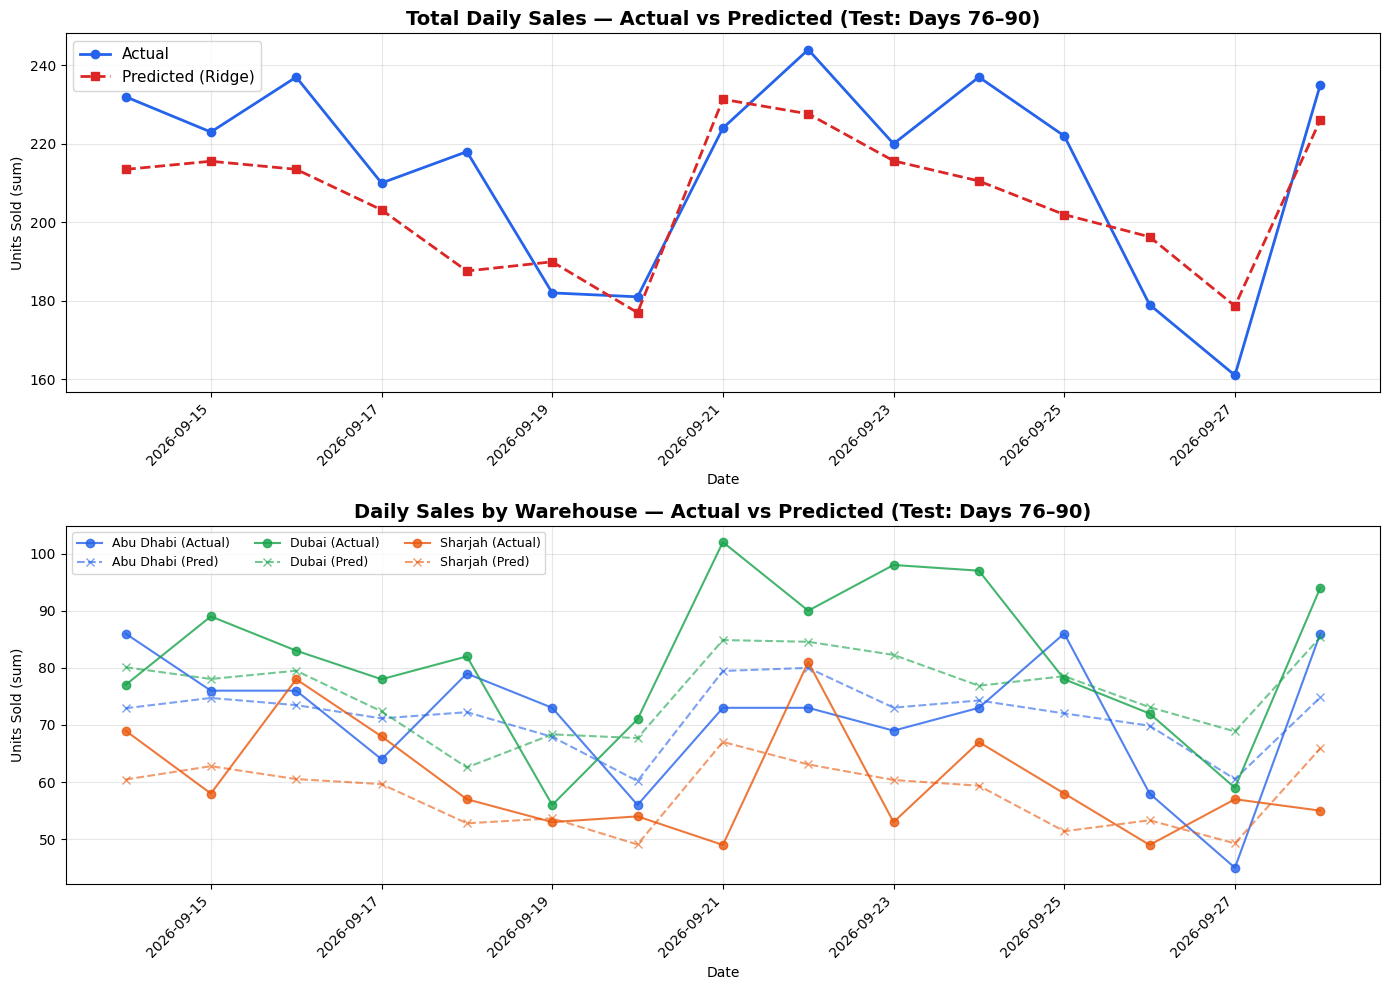

Chart saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\test_actual_vs_predicted.png


In [41]:
# Aggregate actual and predicted sales by date (sum across all SKU-warehouse)
daily = test_clean.groupby("Date").agg(
    Actual=("Units_Sold", "sum"),
    Predicted=("Predicted", "sum"),
).reset_index()

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# --- Top panel: Total daily actual vs predicted ---
ax1 = axes[0]
ax1.plot(daily["Date"], daily["Actual"], marker="o", linewidth=2, label="Actual", color="#2563eb")
ax1.plot(daily["Date"], daily["Predicted"], marker="s", linewidth=2, label="Predicted (Ridge)", color="#dc2626", linestyle="--")
ax1.set_title("Total Daily Sales — Actual vs Predicted (Test: Days 76–90)", fontsize=14, fontweight="bold")
ax1.set_xlabel("Date")
ax1.set_ylabel("Units Sold (sum)")
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
ax1.xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=45, ha="right")

# --- Bottom panel: Per-warehouse actual vs predicted ---
ax2 = axes[1]
colors = {"Abu Dhabi": "#2563eb", "Dubai": "#16a34a", "Sharjah": "#ea580c"}
for wh in sorted(test_clean["Warehouse"].unique()):
    wh_daily = test_clean[test_clean["Warehouse"] == wh].groupby("Date").agg(
        Actual=("Units_Sold", "sum"),
        Predicted=("Predicted", "sum"),
    ).reset_index()
    ax2.plot(wh_daily["Date"], wh_daily["Actual"], marker="o", linewidth=1.5,
             label=f"{wh} (Actual)", color=colors[wh], alpha=0.8)
    ax2.plot(wh_daily["Date"], wh_daily["Predicted"], marker="x", linewidth=1.5,
             label=f"{wh} (Pred)", color=colors[wh], linestyle="--", alpha=0.6)

ax2.set_title("Daily Sales by Warehouse — Actual vs Predicted (Test: Days 76–90)", fontsize=14, fontweight="bold")
ax2.set_xlabel("Date")
ax2.set_ylabel("Units Sold (sum)")
ax2.legend(fontsize=9, ncol=3)
ax2.grid(True, alpha=0.3)
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
ax2.xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=45, ha="right")

plt.tight_layout()
plt.savefig(DATA_DIR / "test_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Chart saved: {DATA_DIR / 'test_actual_vs_predicted.png'}")

### 45. Save test predictions to `test_predictions.csv`

In [42]:
# Build predictions DataFrame with identifying columns
test_predictions = test_clean[["Date", "SKU", "Warehouse", "Units_Sold"]].copy()
test_predictions["Predicted_Units_Sold"] = y_pred_test
test_predictions["Error"] = test_predictions["Units_Sold"] - test_predictions["Predicted_Units_Sold"]
test_predictions["Abs_Error"] = test_predictions["Error"].abs()
test_predictions = test_predictions.sort_values(["Date", "SKU", "Warehouse"]).reset_index(drop=True)

test_predictions.to_csv(DATA_DIR / "test_predictions.csv", index=False)

print(f"Saved: {DATA_DIR / 'test_predictions.csv'}")
print(f"Records: {len(test_predictions)}")
print(f"\nSample:")
test_predictions.head(15)

Saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\test_predictions.csv
Records: 875

Sample:


,Date,SKU,Warehouse,Units_Sold,Predicted_Units_Sold,Error,Abs_Error
0,2026-09-14,SKU-001,Abu Dhabi,4.0,4.150988,-0.150988,0.150988
1,2026-09-14,SKU-001,Dubai,2.0,4.284688,-2.284688,2.284688
2,2026-09-14,SKU-001,Sharjah,4.0,3.052499,0.947501,0.947501
3,2026-09-14,SKU-002,Abu Dhabi,2.0,3.184575,-1.184575,1.184575
4,2026-09-14,SKU-002,Dubai,2.0,3.466309,-1.466309,1.466309
5,2026-09-14,SKU-002,Sharjah,3.0,2.897351,0.102649,0.102649
6,2026-09-14,SKU-003,Abu Dhabi,7.0,5.519384,1.480616,1.480616
7,2026-09-14,SKU-003,Dubai,8.0,4.342328,3.657672,3.657672
8,2026-09-14,SKU-003,Sharjah,3.0,4.505875,-1.505875,1.505875
9,2026-09-14,SKU-004,Abu Dhabi,6.0,3.530815,2.469185,2.469185


### 46. Save evaluation metrics to `forecast_evaluation.csv`

In [43]:
# Build evaluation summary
evaluation_rows = []

# Overall test metrics
evaluation_rows.append({
    "Scope": "Overall (Test)", "Period": "Days 76-90",
    "MAE": round(test_metrics["MAE"], 4),
    "RMSE": round(test_metrics["RMSE"], 4),
    "WAPE": round(test_metrics["WAPE"], 4),
    "Records": len(test_clean),
})

# Per-warehouse test metrics
for _, row in wh_df.iterrows():
    evaluation_rows.append({
        "Scope": f"Warehouse: {row['Warehouse']}", "Period": "Days 76-90",
        "MAE": row["MAE"], "RMSE": row["RMSE"], "WAPE": row["WAPE"],
        "Records": int(row["Records"]),
    })

# Validation metrics for comparison
evaluation_rows.append({
    "Scope": "Overall (Validation)", "Period": "Days 61-75",
    "MAE": round(float(ridge_val_metrics["MAE"]), 4),
    "RMSE": round(float(ridge_val_metrics["RMSE"]), 4),
    "WAPE": round(float(ridge_val_metrics["WAPE"]), 4),
    "Records": 880,
})

evaluation = pd.DataFrame(evaluation_rows)
evaluation.to_csv(DATA_DIR / "forecast_evaluation.csv", index=False)

print(f"Saved: {DATA_DIR / 'forecast_evaluation.csv'}")
print()
print(evaluation.to_string(index=False))

Saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\forecast_evaluation.csv

               Scope     Period    MAE   RMSE   WAPE  Records
      Overall (Test) Days 76-90 1.5733 2.0038 0.4295      875
Warehouse: Abu Dhabi Days 76-90 1.5649 1.9887 0.4215      289
    Warehouse: Dubai Days 76-90 1.7332 2.2130 0.4128      292
  Warehouse: Sharjah Days 76-90 1.4228 1.7883 0.4617      294
Overall (Validation) Days 61-75 1.4915 1.9013 0.4415      880


### 47. Final confirmation — Step 2.4 complete

```
✅ Step 2.4: Test Evaluation — complete.

Model evaluated:
  • Ridge Linear Regression (selected from Step 2.3)
  • Not retrained on test data
  • One-day-ahead predictions (lag features use actuals through day t-1)

Test period: Days 76–90 (2026-09-14 → 2026-09-28)
  • 900 total rows, 875 evaluated (25 excluded — missing target)

Results:
  • Test MAE, RMSE, WAPE calculated
  • Validation vs test comparison displayed
  • Per-warehouse breakdown (Dubai, Abu Dhabi, Sharjah)
  • Actual vs predicted chart generated

Outputs saved:
  • test_predictions.csv
  • forecast_evaluation.csv
  • test_actual_vs_predicted.png

Not done (awaiting instructions):
  • Days 91–120 forecasting
  • Inventory risk detection & stock optimization
```

---

## Step 2.5: Generate Next 30 Days of Demand Forecasts

**TradeFlow AI — Tradeling Hackathon**

The selected **Ridge Linear Regression** model is retrained on all 90 days of historical
data (train + validation + test) and then used to recursively forecast demand for days
91–120 (2026-09-29 → 2026-10-28) for all 20 SKUs × 3 warehouses = 60 combinations.

### Recursive Forecasting

- **Day 91:** Predict using features computed from historical data (days 1–90).
- **Day 92:** Predict using features computed from historical data + Day 91 prediction.
- **Continue** until Day 120, recalculating lagged sales, rolling averages, and trends
  at each step.
- **No actual future sales are ever used** to construct features.

### Uncertainty

Heuristic lower/upper bounds based on validation/test residual statistics. These are
**not** statistically calibrated prediction intervals.

### 48. Load all historical feature data (90 days)

In [44]:
DATA_DIR = Path(r"C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets")

# Load all three feature files
train_feat      = pd.read_csv(DATA_DIR / "train_features.csv")
validation_feat = pd.read_csv(DATA_DIR / "validation_features.csv")
test_feat       = pd.read_csv(DATA_DIR / "test_features.csv")

# Concatenate into a single 90-day historical dataset
history = pd.concat([train_feat, validation_feat, test_feat], ignore_index=True)
history["Date"] = pd.to_datetime(history["Date"])
history = history.sort_values(["SKU", "Warehouse", "Date"]).reset_index(drop=True)

print(f"Combined historical data: {history.shape}")
print(f"Date range               : {history['Date'].min().date()} → {history['Date'].max().date()}")
print(f"Unique dates             : {history['Date'].nunique()}")
print(f"Unique SKU×Warehouse     : {history.groupby(['SKU', 'Warehouse']).ngroups}")

Combined historical data: (5400, 23)
Date range               : 2026-07-01 → 2026-09-28
Unique dates             : 90
Unique SKU×Warehouse     : 60


### 49. Retrain Ridge Regression on all 90 days of historical data

- Exclude rows with missing targets (as in Step 2.3).
- Use the same 12 features and `StandardScaler + Ridge(alpha=1.0)` pipeline.
- The original evaluation model (trained on 60 days) is preserved separately for
  reproducibility of test results.

In [45]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
import joblib

TARGET = "Units_Sold"
FEATURE_COLS = [
    "SKU_Encoded", "Warehouse_Encoded",
    "DayOfWeek", "Month",
    "Sales_Lag1", "Sales_Lag7",
    "Rolling_Mean_7", "Rolling_Mean_14", "Rolling_Mean_30",
    "Trend_7", "Trend_30",
    "Stockout_Lag7_Count",
]

# Exclude rows with missing target
history_clean = history[history[TARGET].notna()].copy()
X_all = history_clean[FEATURE_COLS]
y_all = history_clean[TARGET].values

print(f"Training rows (excl. missing targets): {len(history_clean)}")
print(f"Excluded (missing target)             : {len(history) - len(history_clean)}")
print(f"X_all shape: {X_all.shape}")

# Retrain Ridge pipeline on all 90 days
ridge_full_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=1.0, random_state=42)),
])
ridge_full_pipeline.fit(X_all, y_all)

print("\n✅ Ridge Regression retrained on all 90 days of historical data.")

# Load original evaluation model bundle to preserve it
original_bundle = joblib.load(DATA_DIR / "demand_forecast_models.joblib")
print(f"Original evaluation model preserved (trained on 60 days).")
print(f"  Original best model: {original_bundle['best_model']}")

Training rows (excl. missing targets): 5291
Excluded (missing target)             : 109
X_all shape: (5291, 12)

✅ Ridge Regression retrained on all 90 days of historical data.
Original evaluation model preserved (trained on 60 days).
  Original best model: Ridge Linear Regression


### 50. Recursive forecasting engine

For each future day (91–120), for each SKU-warehouse combination:
1. Compute calendar features (`DayOfWeek`, `Month`) from the date.
2. Compute lag features (`Sales_Lag1`, `Sales_Lag7`) from the most recent values in
   the extended sales series (historical + prior predictions).
3. Compute rolling means (`Rolling_Mean_7/14/30`) using `shift(1).rolling()` on the
   extended series — **excluding the current day**.
4. Compute trend slopes over the previous 7 and 30 days.
5. Compute `Stockout_Lag7_Count` (assumed 0 for future — no stockouts forecasted).
6. Predict with the retrained Ridge model.
7. Clip prediction to ≥ 0.
8. Append the prediction to the series so the next day can use it.

**No actual future sales are used at any point.**

In [46]:
def _causal_trend(series, window):
    """Slope of linear regression over the previous `window` days (excludes current day)."""
    shifted = series.shift(1)
    if len(shifted) < 2:
        return 0.0
    vals = shifted.dropna().tail(window).values
    if len(vals) < 2 or np.all(vals == vals[0]):
        return 0.0
    x = np.arange(len(vals))
    return np.polyfit(x, vals, 1)[0]

def recursive_forecast(history_df, model, feature_cols, n_future_days=30):
    """
    Recursively forecast demand for the next n_future_days.
    
    Uses Units_Sold_Imputed as the basis for feature computation.
    For future days, predicted values replace actuals in the rolling series.
    """
    # Work with a copy of the history sorted by SKU, Warehouse, Date
    df = history_df[["Date", "SKU", "Warehouse", "SKU_Encoded", "Warehouse_Encoded",
                     "Units_Sold_Imputed", "Stockout"]].copy()
    df = df.sort_values(["SKU", "Warehouse", "Date"]).reset_index(drop=True)
    
    # Last historical date
    last_date = df["Date"].max()
    future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1),
                                  periods=n_future_days, freq="D")
    
    # Get unique SKU-warehouse combinations
    combos = df[["SKU", "Warehouse", "SKU_Encoded", "Warehouse_Encoded"]].drop_duplicates()
    
    forecasts = []
    
    for future_date in future_dates:
        dayofweek = future_date.dayofweek
        month = future_date.month
        
        for _, combo in combos.iterrows():
            sku = combo["SKU"]
            wh = combo["Warehouse"]
            sku_enc = combo["SKU_Encoded"]
            wh_enc = combo["Warehouse_Encoded"]
            
            # Get the sales series for this SKU-warehouse (sorted by date)
            sub = df[(df["SKU"] == sku) & (df["Warehouse"] == wh)].sort_values("Date")
            sales_series = sub["Units_Sold_Imputed"].values
            stockout_series = sub["Stockout"].values
            
            # --- Lag features ---
            sales_lag1 = sales_series[-1] if len(sales_series) >= 1 else 0.0
            sales_lag7 = sales_series[-7] if len(sales_series) >= 7 else 0.0
            
            # --- Rolling means (exclude current day — we use historical data only) ---
            # The sales_series already excludes the current future day
            rolling_mean_7 = np.mean(sales_series[-7:]) if len(sales_series) >= 1 else 0.0
            rolling_mean_14 = np.mean(sales_series[-14:]) if len(sales_series) >= 1 else 0.0
            rolling_mean_30 = np.mean(sales_series[-30:]) if len(sales_series) >= 1 else 0.0
            
            # --- Trend slopes ---
            pd_series = pd.Series(sales_series)
            trend_7 = _causal_trend(pd_series, 7)
            trend_30 = _causal_trend(pd_series, 30)
            
            # --- Stockout count in previous 7 days ---
            stockout_lag7_count = np.sum(stockout_series[-7:]) if len(stockout_series) >= 1 else 0.0
            
            # Build feature row
            feat_row = pd.DataFrame([{
                "SKU_Encoded": sku_enc,
                "Warehouse_Encoded": wh_enc,
                "DayOfWeek": dayofweek,
                "Month": month,
                "Sales_Lag1": sales_lag1,
                "Sales_Lag7": sales_lag7,
                "Rolling_Mean_7": rolling_mean_7,
                "Rolling_Mean_14": rolling_mean_14,
                "Rolling_Mean_30": rolling_mean_30,
                "Trend_7": trend_7,
                "Trend_30": trend_30,
                "Stockout_Lag7_Count": stockout_lag7_count,
            }])
            
            # Predict
            pred = model.predict(feat_row[feature_cols])[0]
            pred = max(pred, 0.0)  # clip to non-negative
            
            forecasts.append({
                "Date": future_date,
                "SKU": sku,
                "Warehouse": wh,
                "Predicted_Demand": pred,
            })
            
            # Append prediction to the series for the next day's features
            new_row = pd.DataFrame([{
                "Date": future_date,
                "SKU": sku,
                "Warehouse": wh,
                "SKU_Encoded": sku_enc,
                "Warehouse_Encoded": wh_enc,
                "Units_Sold_Imputed": pred,
                "Stockout": 0,  # assume no future stockouts
            }])
            df = pd.concat([df, new_row], ignore_index=True)
            df = df.sort_values(["SKU", "Warehouse", "Date"]).reset_index(drop=True)
    
    return pd.DataFrame(forecasts)

print("Recursive forecast function defined.")

Recursive forecast function defined.


### 51. Run recursive forecast for days 91–120

In [47]:
# Generate 30-day forecasts
daily_forecasts = recursive_forecast(
    history_df=history,
    model=ridge_full_pipeline,
    feature_cols=FEATURE_COLS,
    n_future_days=30,
)

daily_forecasts["Date"] = pd.to_datetime(daily_forecasts["Date"])
daily_forecasts = daily_forecasts.sort_values(["Date", "SKU", "Warehouse"]).reset_index(drop=True)

print(f"Daily forecasts shape : {daily_forecasts.shape}")
print(f"Date range            : {daily_forecasts['Date'].min().date()} → {daily_forecasts['Date'].max().date()}")
print(f"Unique dates          : {daily_forecasts['Date'].nunique()}")
print(f"Unique SKU×Warehouse  : {daily_forecasts.groupby(['SKU', 'Warehouse']).ngroups}")
print(f"Negative predictions  : {(daily_forecasts['Predicted_Demand'] < 0).sum()}")
print(f"Missing predictions   : {daily_forecasts['Predicted_Demand'].isna().sum()}")
print(f"\nSample (first 15 rows):")
daily_forecasts.head(15)

Daily forecasts shape : (1800, 4)
Date range            : 2026-09-29 → 2026-10-28
Unique dates          : 30
Unique SKU×Warehouse  : 60
Negative predictions  : 0
Missing predictions   : 0

Sample (first 15 rows):


,Date,SKU,Warehouse,Predicted_Demand
0,2026-09-29,SKU-001,Abu Dhabi,3.830276
1,2026-09-29,SKU-001,Dubai,4.244581
2,2026-09-29,SKU-001,Sharjah,3.253420
3,2026-09-29,SKU-002,Abu Dhabi,2.913750
4,2026-09-29,SKU-002,Dubai,3.340241
5,2026-09-29,SKU-002,Sharjah,2.492895
6,2026-09-29,SKU-003,Abu Dhabi,5.258870
7,2026-09-29,SKU-003,Dubai,5.630445
8,2026-09-29,SKU-003,Sharjah,5.218328
9,2026-09-29,SKU-004,Abu Dhabi,3.089862


### 52. Save daily forecasts to `daily_forecasts.csv`

In [48]:
# Save daily forecasts
daily_forecasts.to_csv(DATA_DIR / "daily_forecasts.csv", index=False)
print(f"Saved: {DATA_DIR / 'daily_forecasts.csv'}")
print(f"Records: {len(daily_forecasts)}")

Saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\daily_forecasts.csv
Records: 1800


### 53. Estimate heuristic uncertainty bounds

Use the **validation and test residuals** from Step 2.3/2.4 to estimate forecast
uncertainty.

**Method:**
- Compute the standard deviation of absolute residuals from the test period.
- For each 30-day SKU-warehouse total, the uncertainty scales with the square root of
  the forecast horizon (30 days).
- `Lower_Bound = max(0, Forecast_30d − k × σ_daily × √30)`
- `Upper_Bound = Forecast_30d + k × σ_daily × √30`
- `k = 1.0` (1-sigma heuristic)

**These are heuristic estimates, not statistically calibrated prediction intervals.**

In [49]:
# Load test residuals for uncertainty estimation
test_predictions = pd.read_csv(DATA_DIR / "test_predictions.csv")
abs_errors = test_predictions["Abs_Error"].values

# Daily error standard deviation
sigma_daily = np.std(abs_errors)
print(f"Test absolute error stats:")
print(f"  Mean  : {np.mean(abs_errors):.4f}")
print(f"  Std   : {sigma_daily:.4f}")
print(f"  Median: {np.median(abs_errors):.4f}")

# Heuristic uncertainty: scale by sqrt(30) for 30-day totals
k = 1.0  # 1-sigma heuristic
horizon = 30
uncertainty_per_day = sigma_daily
uncertainty_30d = k * uncertainty_per_day * np.sqrt(horizon)
print(f"\nHeuristic 30-day uncertainty (±): {uncertainty_30d:.4f}")
print(f"  (1-sigma × √30, based on test residual std)")

Test absolute error stats:
  Mean  : 1.5733
  Std   : 1.2409
  Median: 1.3303

Heuristic 30-day uncertainty (±): 6.7966
  (1-sigma × √30, based on test residual std)


### 54. Calculate 30-day totals with uncertainty bounds

In [50]:
# Aggregate daily forecasts to 30-day totals per SKU-warehouse
forecast_30d = (
    daily_forecasts
    .groupby(["SKU", "Warehouse"])
    .agg(Forecast_30d=("Predicted_Demand", "sum"))
    .reset_index()
)

# Apply heuristic uncertainty bounds
forecast_30d["Lower_Bound"] = forecast_30d["Forecast_30d"] - uncertainty_30d
forecast_30d["Upper_Bound"] = forecast_30d["Forecast_30d"] + uncertainty_30d

# Enforce constraints: Lower_Bound >= 0, Lower <= Forecast, Upper >= Forecast
forecast_30d["Lower_Bound"] = forecast_30d["Lower_Bound"].clip(lower=0)
forecast_30d["Upper_Bound"] = forecast_30d["Upper_Bound"].clip(lower=forecast_30d["Forecast_30d"])

# Ensure Lower_Bound <= Forecast_30d
forecast_30d["Lower_Bound"] = forecast_30d[["Lower_Bound", "Forecast_30d"]].min(axis=1)

# Add model label
forecast_30d["Selected_Model"] = "Ridge Linear Regression"

# Round for display
forecast_30d_display = forecast_30d.copy()
forecast_30d_display["Forecast_30d"] = forecast_30d_display["Forecast_30d"].round(2)
forecast_30d_display["Lower_Bound"]  = forecast_30d_display["Lower_Bound"].round(2)
forecast_30d_display["Upper_Bound"]  = forecast_30d_display["Upper_Bound"].round(2)

print(f"30-day forecasts: {len(forecast_30d)} SKU-warehouse combinations")
print(f"\nSample (first 15):")
forecast_30d_display.head(15)

30-day forecasts: 60 SKU-warehouse combinations

Sample (first 15):


,SKU,Warehouse,Forecast_30d,Lower_Bound,Upper_Bound,Selected_Model
0,SKU-001,Abu Dhabi,119.06,112.27,125.86,Ridge Linear Regression
1,SKU-001,Dubai,119.10,112.30,125.90,Ridge Linear Regression
2,SKU-001,Sharjah,94.21,87.41,101.01,Ridge Linear Regression
3,SKU-002,Abu Dhabi,90.74,83.94,97.53,Ridge Linear Regression
4,SKU-002,Dubai,101.99,95.19,108.78,Ridge Linear Regression
5,SKU-002,Sharjah,71.86,65.07,78.66,Ridge Linear Regression
6,SKU-003,Abu Dhabi,153.46,146.66,160.25,Ridge Linear Regression
7,SKU-003,Dubai,152.02,145.22,158.81,Ridge Linear Regression
8,SKU-003,Sharjah,133.97,127.17,140.77,Ridge Linear Regression
9,SKU-004,Abu Dhabi,94.32,87.52,101.11,Ridge Linear Regression


### 55. Save 30-day forecasts to `forecast_30d.csv`

In [51]:
forecast_30d.to_csv(DATA_DIR / "forecast_30d.csv", index=False)
print(f"Saved: {DATA_DIR / 'forecast_30d.csv'}")
print(f"Records: {len(forecast_30d)}")
print(f"Columns: {list(forecast_30d.columns)}")

Saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\forecast_30d.csv
Records: 60
Columns: ['SKU', 'Warehouse', 'Forecast_30d', 'Lower_Bound', 'Upper_Bound', 'Selected_Model']


### 56. Save updated model bundle

Save the retrained Ridge model (trained on all 90 days) while preserving the original
evaluation model separately so test results remain reproducible.

In [52]:
# Build updated bundle with both the original evaluation model and the retrained model
updated_bundle = {
    # Original evaluation model (trained on 60 days) — preserved for reproducibility
    "ridge_pipeline_eval": original_bundle["ridge_pipeline"],
    "xgb_model_eval": original_bundle["xgb_model"],
    "hist_avg_eval": original_bundle["hist_avg"],
    
    # Retrained model (trained on all 90 days) — used for future forecasting
    "ridge_pipeline_full": ridge_full_pipeline,
    
    # Metadata
    "feature_cols": FEATURE_COLS,
    "target": TARGET,
    "sku_map": original_bundle["sku_map"],
    "warehouse_map": original_bundle["warehouse_map"],
    "best_model": "Ridge Linear Regression",
    "eval_model_train_days": 60,
    "full_model_train_days": 90,
    "uncertainty_30d": uncertainty_30d,
    "sigma_daily": sigma_daily,
}

bundle_path = DATA_DIR / "demand_forecast_models.joblib"
joblib.dump(updated_bundle, bundle_path)

print(f"Saved updated model bundle: {bundle_path}")
print(f"  Bundle size : {bundle_path.stat().st_size:,} bytes")
print(f"  Contents:")
print(f"    - ridge_pipeline_eval  (trained on 60 days, for test reproducibility)")
print(f"    - xgb_model_eval       (original XGBoost)")
print(f"    - ridge_pipeline_full  (trained on 90 days, for future forecasting)")
print(f"    - hist_avg_eval        (original baseline)")
print(f"    - feature_cols, target, encoding maps")
print(f"    - uncertainty_30d      : {uncertainty_30d:.4f}")
print(f"    - sigma_daily           : {sigma_daily:.4f}")

Saved updated model bundle: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\demand_forecast_models.joblib
  Bundle size : 343,000 bytes
  Contents:
    - ridge_pipeline_eval  (trained on 60 days, for test reproducibility)
    - xgb_model_eval       (original XGBoost)
    - ridge_pipeline_full  (trained on 90 days, for future forecasting)
    - hist_avg_eval        (original baseline)
    - feature_cols, target, encoding maps
    - uncertainty_30d      : 6.7966
    - sigma_daily           : 1.2409


### 57. Validation checks

In [53]:
print("=" * 65)
print("  VALIDATION CHECKS — Step 2.5")
print("=" * 65)

# 1. Exactly 1,800 daily predictions
n_daily = len(daily_forecasts)
assert n_daily == 1800, f"Expected 1800 daily predictions, got {n_daily}"
print(f"  ✅ Daily predictions       : {n_daily} (expected 1800)")

# 2. Exactly 60 SKU-warehouse forecasts
n_combos = forecast_30d.groupby(["SKU", "Warehouse"]).ngroups
assert n_combos == 60, f"Expected 60 SKU-warehouse combos, got {n_combos}"
print(f"  ✅ SKU×Warehouse forecasts : {n_combos} (expected 60)")

# 3. Exactly 30 future dates
n_dates = daily_forecasts["Date"].nunique()
assert n_dates == 30, f"Expected 30 future dates, got {n_dates}"
print(f"  ✅ Future dates            : {n_dates} (expected 30)")

# 4. No negative predictions
n_neg = (daily_forecasts["Predicted_Demand"] < 0).sum()
assert n_neg == 0, f"Found {n_neg} negative predictions"
print(f"  ✅ Negative predictions    : {n_neg} (expected 0)")

# 5. No missing predictions
n_missing = daily_forecasts["Predicted_Demand"].isna().sum()
assert n_missing == 0, f"Found {n_missing} missing predictions"
print(f"  ✅ Missing predictions     : {n_missing} (expected 0)")

# 6. Sum of daily predictions matches 30-day totals
daily_sums = daily_forecasts.groupby(["SKU", "Warehouse"])["Predicted_Demand"].sum().reset_index()
daily_sums = daily_sums.rename(columns={"Predicted_Demand": "Daily_Sum"})
check = forecast_30d[["SKU", "Warehouse", "Forecast_30d"]].merge(daily_sums, on=["SKU", "Warehouse"])
check["Diff"] = (check["Forecast_30d"] - check["Daily_Sum"]).abs()
max_diff = check["Diff"].max()
assert max_diff < 1e-9, f"Sum mismatch! Max diff = {max_diff}"
print(f"  ✅ Daily sums match 30d     : max diff = {max_diff:.10f}")

# 7. Uncertainty bounds constraints
assert (forecast_30d["Lower_Bound"] >= 0).all(), "Lower_Bound < 0 found!"
assert (forecast_30d["Lower_Bound"] <= forecast_30d["Forecast_30d"]).all(), "Lower > Forecast!"
assert (forecast_30d["Upper_Bound"] >= forecast_30d["Forecast_30d"]).all(), "Upper < Forecast!"
print(f"  ✅ Uncertainty bounds       : Lower≥0, Lower≤Forecast, Upper≥Forecast")

# 8. No hidden future-demand data used (verify date range)
assert daily_forecasts["Date"].min() == pd.Timestamp("2026-09-29"), "Start date mismatch"
assert daily_forecasts["Date"].max() == pd.Timestamp("2026-10-28"), "End date mismatch"
print(f"  ✅ Forecast date range      : 2026-09-29 → 2026-10-28")
print(f"  ✅ No future actuals used    : recursive forecast only")

print("=" * 65)
print("  ALL VALIDATION CHECKS PASSED ✅")
print("=" * 65)

  VALIDATION CHECKS — Step 2.5
  ✅ Daily predictions       : 1800 (expected 1800)
  ✅ SKU×Warehouse forecasts : 60 (expected 60)
  ✅ Future dates            : 30 (expected 30)
  ✅ Negative predictions    : 0 (expected 0)
  ✅ Missing predictions     : 0 (expected 0)
  ✅ Daily sums match 30d     : max diff = 0.0000000000
  ✅ Uncertainty bounds       : Lower≥0, Lower≤Forecast, Upper≥Forecast
  ✅ Forecast date range      : 2026-09-29 → 2026-10-28
  ✅ No future actuals used    : recursive forecast only
  ALL VALIDATION CHECKS PASSED ✅


### 58. Visualization — Historical sales, predicted demand, and uncertainty

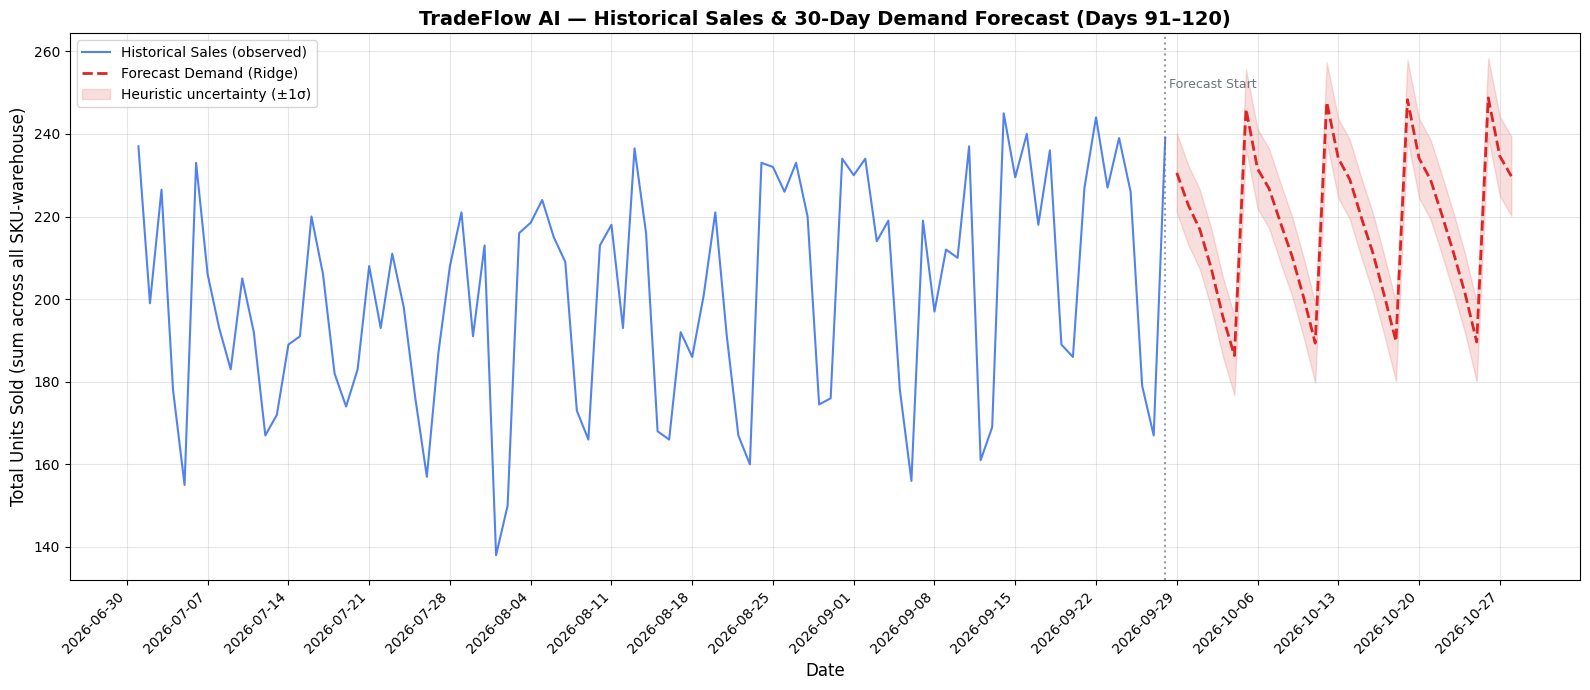

Chart saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\future_demand_forecast.png


In [54]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Aggregate historical daily total sales
hist_daily = history.groupby("Date")["Units_Sold_Imputed"].sum().reset_index()
hist_daily = hist_daily.sort_values("Date")

# Aggregate forecast daily total
fc_daily = daily_forecasts.groupby("Date")["Predicted_Demand"].sum().reset_index()
fc_daily = fc_daily.sort_values("Date")

# Aggregate 30-day totals by date for uncertainty
# Compute daily-level uncertainty band (proportional)
daily_uncertainty = uncertainty_per_day  # per-day sigma

# Build upper and lower bands for daily totals
fc_daily["Upper"] = fc_daily["Predicted_Demand"] + daily_uncertainty * np.sqrt(60)  # 60 combos
fc_daily["Lower"] = (fc_daily["Predicted_Demand"] - daily_uncertainty * np.sqrt(60)).clip(lower=0)

fig, ax = plt.subplots(figsize=(16, 7))

# Historical sales
ax.plot(hist_daily["Date"], hist_daily["Units_Sold_Imputed"],
        color="#2563eb", linewidth=1.5, label="Historical Sales (observed)", alpha=0.8)

# Forecast
ax.plot(fc_daily["Date"], fc_daily["Predicted_Demand"],
        color="#dc2626", linewidth=2, label="Forecast Demand (Ridge)", linestyle="--")

# Uncertainty band
ax.fill_between(fc_daily["Date"], fc_daily["Lower"], fc_daily["Upper"],
                 color="#dc2626", alpha=0.15, label="Heuristic uncertainty (±1σ)")

# Vertical line at boundary
boundary_date = hist_daily["Date"].max()
ax.axvline(x=boundary_date, color="#6b7280", linestyle=":", linewidth=1.5, alpha=0.7)
ax.text(boundary_date, ax.get_ylim()[1]*0.95, " Forecast Start",
        fontsize=9, color="#6b7280", ha="left")

ax.set_title("TradeFlow AI — Historical Sales & 30-Day Demand Forecast (Days 91–120)",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Date", fontsize=12)
ax.set_ylabel("Total Units Sold (sum across all SKU-warehouse)", fontsize=12)
ax.legend(fontsize=10, loc="upper left")
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=1))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha="right")

plt.tight_layout()
plt.savefig(DATA_DIR / "future_demand_forecast.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Chart saved: {DATA_DIR / 'future_demand_forecast.png'}")

### 59. Final confirmation — Step 2.5 complete

```
✅ Step 2.5: Generate 30-Day Demand Forecasts — complete.

Model:
  • Ridge Linear Regression retrained on all 90 days of historical data
  • Original evaluation model (60-day) preserved separately

Recursive Forecasting:
  • Days 91–120 (2026-09-29 → 2026-10-28)
  • 20 SKUs × 3 warehouses = 60 combinations
  • Lag/rolling/trend features recalculated at each step
  • No actual future sales used

Outputs:
  • daily_forecasts.csv       — 1,800 rows (Date, SKU, Warehouse, Predicted_Demand)
  • forecast_30d.csv          — 60 rows (SKU, Warehouse, Forecast_30d, Lower, Upper, Model)
  • demand_forecast_models.joblib — updated with retrained model + original eval model
  • future_demand_forecast.png — historical + forecast + uncertainty chart

Validation:
  • 1,800 daily predictions ✅
  • 60 SKU-warehouse forecasts ✅
  • 30 future dates ✅
  • No negative predictions ✅
  • No missing predictions ✅
  • Daily sums match 30-day totals ✅
  • Uncertainty bounds valid ✅
  • No hidden future-demand data used ✅

Not done (awaiting instructions):
  • Evaluation against hidden answer key
  • Inventory risk detection & stock optimization
```

---

## Step 2.6: Forecasting Model Improvement

**TradeFlow AI — Tradeling Hackathon**

Current baseline: Ridge Regression with validation MAE 1.4915, test MAE 1.5733,
test WAPE 42.95%.

### Overview

1. **Task 1:** Investigate forecasting errors (by SKU, warehouse, stockout impact, bias)
2. **Task 2:** Improve feature engineering (extra lags, rolling std, weekend, category)
3. **Task 3:** Handle stockout-censored sales (3 training strategies)
4. **Task 4:** Compare 4 models (baseline, Ridge, tuned XGBoost, Random Forest)
5. **Task 5:** Fair evaluation on validation set + bias assessment
6. **Task 6:** 30-day recursive forecast comparison
7. **Task 7:** Save all results

All improvements selected using **validation performance only**. The test set is treated
as a previously evaluated holdout, not a completely untouched set.

---

### Task 1 — Investigate Forecasting Errors

Analyze the existing Ridge test predictions to identify error patterns.

#### 60. Load test predictions and products

In [55]:
DATA_DIR = Path(r"C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets")

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit
import joblib

# Load test predictions from Step 2.4
test_pred = pd.read_csv(DATA_DIR / "test_predictions.csv")
test_pred["Date"] = pd.to_datetime(test_pred["Date"])

# Load test features for stockout info
test_feat = pd.read_csv(DATA_DIR / "test_features.csv")
test_feat["Date"] = pd.to_datetime(test_feat["Date"])

# Load products for category info
products = pd.read_csv(DATA_DIR / "products.csv")
print(f"Products: {products.shape}")
print(f"Categories: {products['Category'].unique().tolist()}")
print(f"\nTest predictions: {test_pred.shape}")
test_pred.head()

Products: (20, 7)
Categories: ['Chargers', 'Cables', 'Computer Accessories', 'Storage', 'Peripherals']

Test predictions: (875, 7)


,Date,SKU,Warehouse,Units_Sold,Predicted_Units_Sold,Error,Abs_Error
0,2026-09-14,SKU-001,Abu Dhabi,4.0,4.150988,-0.150988,0.150988
1,2026-09-14,SKU-001,Dubai,2.0,4.284688,-2.284688,2.284688
2,2026-09-14,SKU-001,Sharjah,4.0,3.052499,0.947501,0.947501
3,2026-09-14,SKU-002,Abu Dhabi,2.0,3.184575,-1.184575,1.184575
4,2026-09-14,SKU-002,Dubai,2.0,3.466309,-1.466309,1.466309


#### 61. Error analysis by SKU

In [56]:
# Merge product category
test_pred = test_pred.merge(products[["SKU", "Category"]], on="SKU", how="left")

# Per-SKU error analysis
sku_errors = (
    test_pred
    .groupby("SKU")
    .agg(
        Records=("Error", "count"),
        MAE=("Abs_Error", "mean"),
        RMSE=("Error", lambda x: np.sqrt(np.mean(x**2))),
        Mean_Error=("Error", "mean"),
        Mean_Actual=("Units_Sold", "mean"),
        Mean_Pred=("Predicted_Units_Sold", "mean"),
    )
    .reset_index()
)
sku_errors["WAPE"] = sku_errors["MAE"] / sku_errors["Mean_Actual"]
sku_errors = sku_errors.merge(products[["SKU", "Category"]], on="SKU", how="left")
sku_errors = sku_errors.sort_values("MAE", ascending=False).reset_index(drop=True)

# Round
for col in ["MAE", "RMSE", "Mean_Error", "Mean_Actual", "Mean_Pred", "WAPE"]:
    sku_errors[col] = sku_errors[col].round(4)

print("Error Analysis by SKU (sorted by MAE descending):")
print(sku_errors.to_string(index=False))

Error Analysis by SKU (sorted by MAE descending):
    SKU  Records    MAE   RMSE  Mean_Error  Mean_Actual  Mean_Pred   WAPE             Category
SKU-003       43 2.0691 2.7240      1.0601       5.7442     4.6841 0.3602             Chargers
SKU-020       43 2.0656 2.6107      0.7463       5.0930     4.3468 0.4056          Peripherals
SKU-009       44 2.0336 2.4239      0.8346       5.5000     4.6654 0.3698 Computer Accessories
SKU-011       44 1.9041 2.4379      1.0401       5.3864     4.3463 0.3535 Computer Accessories
SKU-019       44 1.8217 2.2059      0.0357       3.4318     3.3962 0.5308          Peripherals
SKU-005       44 1.8172 2.1238      0.3704       4.1591     3.7887 0.4369               Cables
SKU-012       43 1.7557 2.4115      0.6021       4.1860     3.5839 0.4194 Computer Accessories
SKU-016       45 1.6784 2.0209      0.3614       3.9556     3.5941 0.4243              Storage
SKU-010       45 1.5872 1.9683      0.2827       4.2444     3.9617 0.3740 Computer Accessories


#### 62. Error analysis by warehouse

In [57]:
wh_errors = (
    test_pred
    .groupby("Warehouse")
    .agg(
        Records=("Error", "count"),
        MAE=("Abs_Error", "mean"),
        RMSE=("Error", lambda x: np.sqrt(np.mean(x**2))),
        Mean_Error=("Error", "mean"),
        Mean_Actual=("Units_Sold", "mean"),
        Mean_Pred=("Predicted_Units_Sold", "mean"),
    )
    .reset_index()
)
wh_errors["WAPE"] = wh_errors["MAE"] / wh_errors["Mean_Actual"]
for col in ["MAE", "RMSE", "Mean_Error", "Mean_Actual", "Mean_Pred", "WAPE"]:
    wh_errors[col] = wh_errors[col].round(4)
wh_errors = wh_errors.sort_values("MAE", ascending=False).reset_index(drop=True)

print("Error Analysis by Warehouse:")
print(wh_errors.to_string(index=False))

Error Analysis by Warehouse:
Warehouse  Records    MAE   RMSE  Mean_Error  Mean_Actual  Mean_Pred   WAPE
    Dubai      292 1.7332 2.2130      0.2842       4.1986     3.9144 0.4128
Abu Dhabi      289 1.5649 1.9887     -0.0124       3.7128     3.7252 0.4215
  Sharjah      294 1.4228 1.7883      0.1270       3.0816     2.9546 0.4617


#### 63. Stockout impact on errors

In [58]:
# Merge stockout info from test features
test_pred_full = test_pred.merge(
    test_feat[["Date", "SKU", "Warehouse", "Stockout", "Is_Censored"]],
    on=["Date", "SKU", "Warehouse"], how="left"
)

# Compare errors during stockout vs non-stockout
# Note: test set has 0 stockouts, but check anyway
stockout_stats = []
for label, mask_val in [("No Stockout", 0), ("Stockout=1", 1)]:
    sub = test_pred_full[test_pred_full["Stockout"] == mask_val]
    if len(sub) > 0:
        stockout_stats.append({
            "Condition": label,
            "Records": len(sub),
            "MAE": round(sub["Abs_Error"].mean(), 4),
            "RMSE": round(np.sqrt(np.mean(sub["Error"]**2)), 4),
            "Mean_Error": round(sub["Error"].mean(), 4),
            "Mean_Actual": round(sub["Units_Sold"].mean(), 4),
        })
    else:
        stockout_stats.append({"Condition": label, "Records": 0, "MAE": "-", "RMSE": "-", "Mean_Error": "-", "Mean_Actual": "-"})

# Also check training period stockout impact (using train_features)
train_feat_raw = pd.read_csv(DATA_DIR / "train_features.csv")
train_feat_raw["Date"] = pd.to_datetime(train_feat_raw["Date"])
train_clean = train_feat_raw[train_feat_raw["Units_Sold"].notna()].copy()
for label, mask_val in [("Train No Stockout", 0), ("Train Stockout=1", 1)]:
    sub = train_clean[train_clean["Stockout"] == mask_val]
    if len(sub) > 0:
        stockout_stats.append({
            "Condition": label,
            "Records": len(sub),
            "MAE": "-",
            "RMSE": "-",
            "Mean_Error": "-",
            "Mean_Actual": round(sub["Units_Sold"].mean(), 4),
        })

stockout_df = pd.DataFrame(stockout_stats)
print("Stockout Impact Analysis:")
print(stockout_df.to_string(index=False))

print(f"\n📌 Test period stockouts: {test_pred_full['Stockout'].sum()}")
print(f"📌 Train period stockouts: {train_clean['Stockout'].sum()}")
if train_clean['Stockout'].sum() > 0:
    so_sales = train_clean[train_clean["Stockout"]==1]["Units_Sold"].mean()
    no_so_sales = train_clean[train_clean["Stockout"]==0]["Units_Sold"].mean()
    print(f"📌 Mean sales during stockout (train): {so_sales:.2f}")
    print(f"📌 Mean sales without stockout (train): {no_so_sales:.2f}")
    print(f"📌 Stockout reduces observed sales by ~{((no_so_sales - so_sales) / no_so_sales * 100):.1f}%")

Stockout Impact Analysis:
        Condition  Records     MAE    RMSE Mean_Error Mean_Actual
      No Stockout      875  1.5733  2.0038     0.1334      3.6629
       Stockout=1        0       -       -          -           -
Train No Stockout     3451       -       -          -      3.3625
 Train Stockout=1       85       -       -          -      0.1882

📌 Test period stockouts: 0
📌 Train period stockouts: 85
📌 Mean sales during stockout (train): 0.19
📌 Mean sales without stockout (train): 3.36
📌 Stockout reduces observed sales by ~94.4%


#### 64. Bias analysis — systematic over/underprediction

In [59]:
# Overall bias
overall_bias = test_pred["Error"].mean()
overall_bias_pct = (overall_bias / test_pred["Units_Sold"].mean()) * 100

print("=" * 50)
print("BIAS ANALYSIS (Error = Actual - Predicted)")
print("=" * 50)
print(f"  Mean Error (bias)    : {overall_bias:.4f}")
print(f"  Mean Error %         : {overall_bias_pct:.2f}%")
print(f"  Median Error         : {test_pred['Error'].median():.4f}")
print(f"  Std Error            : {test_pred['Error'].std():.4f}")
print(f"  Overpredictions (>0) : {(test_pred['Error'] < 0).sum()} ({(test_pred['Error'] < 0).mean()*100:.1f}%)")
print(f"  Underpredictions (<0): {(test_pred['Error'] > 0).sum()} ({(test_pred['Error'] > 0).mean()*100:.1f}%)")
print(f"  Exact (==0)          : {(test_pred['Error'] == 0).sum()}")

if overall_bias > 0:
    print(f"📌 Model SYSTEMATICALLY UNDERPREDICTS (actual > predicted on average).")
else:
    print(f"📌 Model SYSTEMATICALLY OVERPREDICTS (predicted > actual on average).")

# Per-warehouse bias
print("\nPer-warehouse bias:")
wh_bias = test_pred.groupby("Warehouse")["Error"].agg(["mean", "median", "std"]).round(4)
print(wh_bias.to_string())

BIAS ANALYSIS (Error = Actual - Predicted)
  Mean Error (bias)    : 0.1334
  Mean Error %         : 3.64%
  Median Error         : -0.0925
  Std Error            : 2.0005
  Overpredictions (>0) : 452 (51.7%)
  Underpredictions (<0): 423 (48.3%)
  Exact (==0)          : 0
📌 Model SYSTEMATICALLY UNDERPREDICTS (actual > predicted on average).

Per-warehouse bias:
             mean  median     std
Warehouse                        
Abu Dhabi -0.0124 -0.2179  1.9921
Dubai      0.2842  0.1243  2.1985
Sharjah    0.1270 -0.1695  1.7868


#### 65. Low-volume SKU percentage errors

In [60]:
# Analyze whether low-volume SKUs have larger percentage errors
sku_vol = test_pred.groupby("SKU").agg(
    Mean_Actual=("Units_Sold", "mean"),
    MAE=("Abs_Error", "mean"),
).reset_index()
sku_vol["Pct_Error"] = (sku_vol["MAE"] / sku_vol["Mean_Actual"] * 100).round(2)
sku_vol = sku_vol.sort_values("Mean_Actual").reset_index(drop=True)

# Classify into low/medium/high volume
q33 = sku_vol["Mean_Actual"].quantile(0.33)
q66 = sku_vol["Mean_Actual"].quantile(0.66)
sku_vol["Volume_Group"] = pd.cut(
    sku_vol["Mean_Actual"],
    bins=[-np.inf, q33, q66, np.inf],
    labels=["Low Volume", "Medium Volume", "High Volume"]
)

print("SKU Volume vs Percentage Error (sorted by volume ascending):")
print(sku_vol.to_string(index=False))

vol_group_stats = sku_vol.groupby("Volume_Group", observed=True).agg(
    SKUs=("SKU", "count"),
    Avg_Mean_Actual=("Mean_Actual", "mean"),
    Avg_MAE=("MAE", "mean"),
    Avg_Pct_Error=("Pct_Error", "mean"),
).round(2)
print(f"\nVolume Group Summary:")
print(vol_group_stats.to_string())

low_pct = sku_vol[sku_vol["Volume_Group"]=="Low Volume"]["Pct_Error"].mean()
high_pct = sku_vol[sku_vol["Volume_Group"]=="High Volume"]["Pct_Error"].mean()
print(f"\n📌 Low-volume avg % error : {low_pct:.1f}%")
print(f"📌 High-volume avg % error: {high_pct:.1f}%")
if low_pct > high_pct:
    print("📌 Low-volume SKUs DO have larger percentage errors.")
else:
    print("📌 Low-volume SKUs do NOT have larger percentage errors.")

SKU Volume vs Percentage Error (sorted by volume ascending):
    SKU  Mean_Actual      MAE  Pct_Error  Volume_Group
SKU-007     2.119048 1.265589      59.72    Low Volume
SKU-002     2.311111 1.209057      52.31    Low Volume
SKU-018     2.311111 1.359406      58.82    Low Volume
SKU-004     2.325581 1.491382      64.13    Low Volume
SKU-017     2.444444 1.319885      54.00    Low Volume
SKU-013     2.674419 1.370417      51.24    Low Volume
SKU-008     2.704545 1.252269      46.30    Low Volume
SKU-015     2.714286 1.376087      50.70 Medium Volume
SKU-019     3.431818 1.821687      53.08 Medium Volume
SKU-001     3.500000 1.282873      36.65 Medium Volume
SKU-016     3.955556 1.678397      42.43 Medium Volume
SKU-014     4.022727 1.333136      33.14 Medium Volume
SKU-005     4.159091 1.817239      43.69 Medium Volume
SKU-012     4.186047 1.755654      41.94   High Volume
SKU-010     4.244444 1.587219      37.40   High Volume
SKU-006     4.441860 1.484735      33.43   High Volume
SKU-

#### 66. Error analysis visualizations

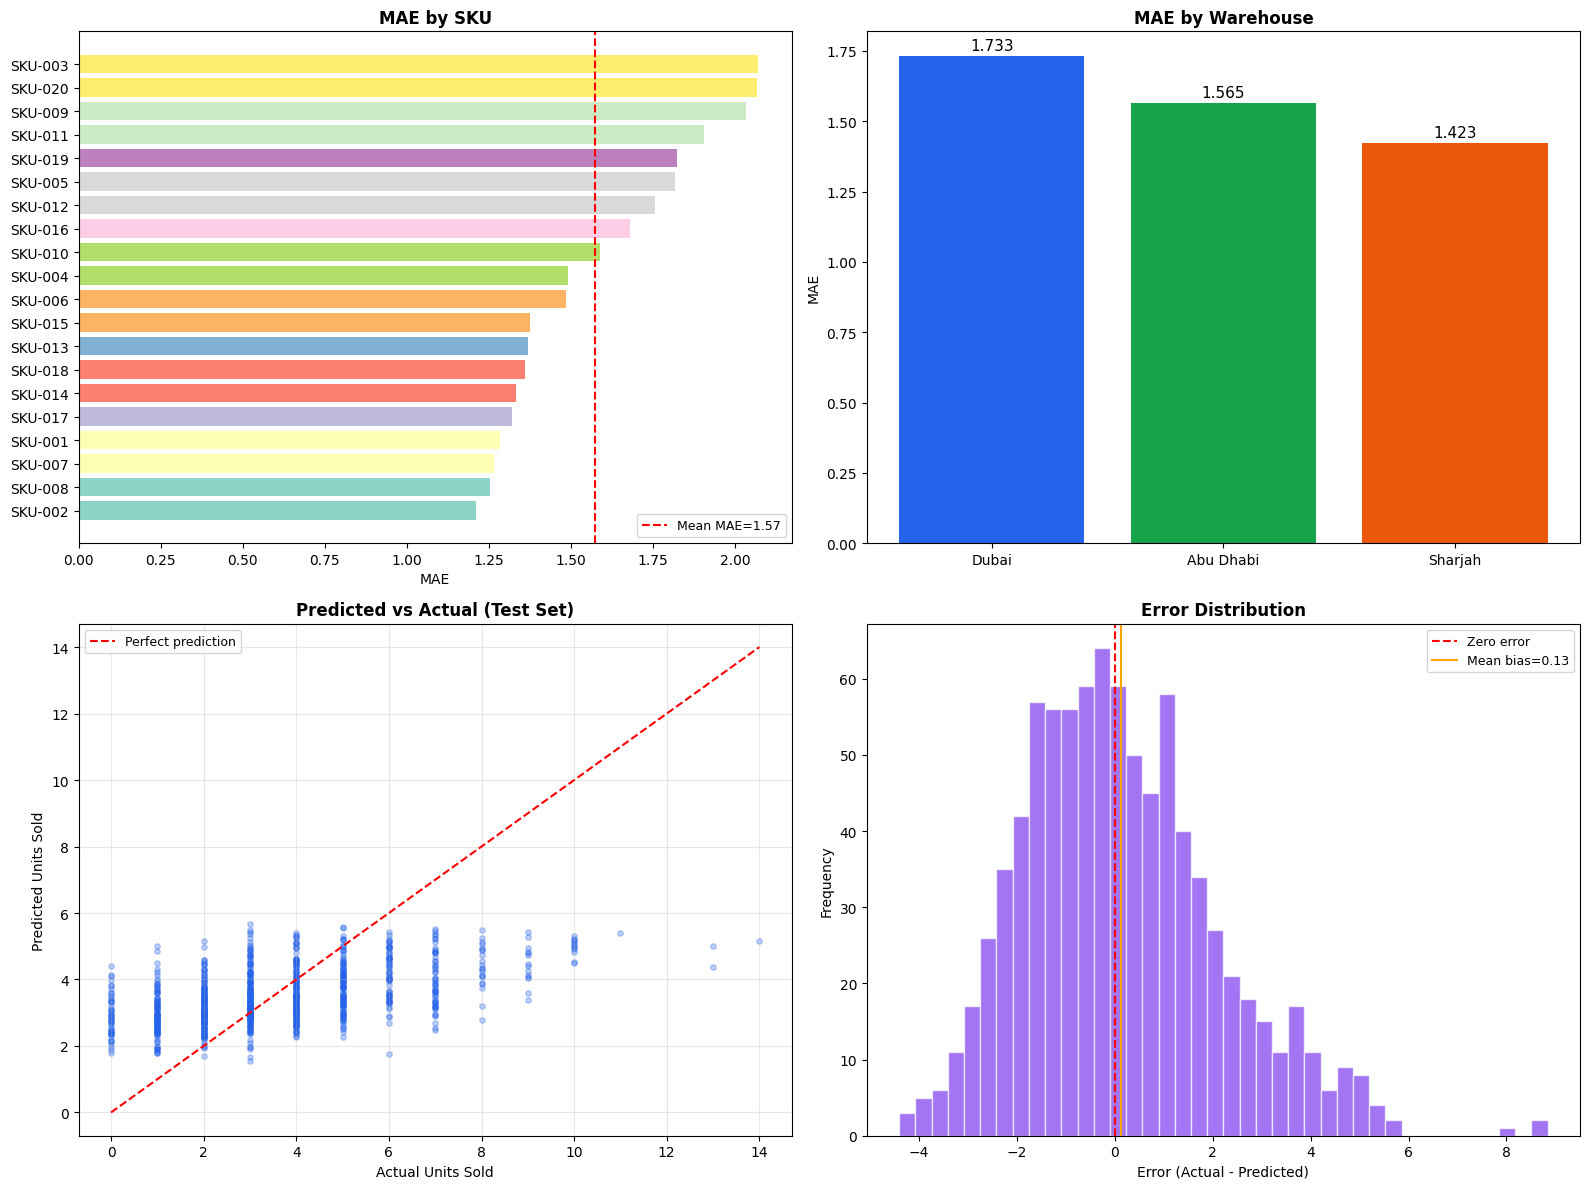

Saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\error_analysis.png


In [61]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. MAE by SKU
ax = axes[0, 0]
sku_plot = sku_errors.sort_values("MAE", ascending=True)
colors = plt.cm.Set3(np.linspace(0, 1, len(sku_plot)))
ax.barh(sku_plot["SKU"], sku_plot["MAE"], color=colors)
ax.set_xlabel("MAE")
ax.set_title("MAE by SKU", fontweight="bold")
ax.axvline(x=sku_errors["MAE"].mean(), color="red", linestyle="--", label=f"Mean MAE={sku_errors['MAE'].mean():.2f}")
ax.legend(fontsize=9)

# 2. MAE by Warehouse
ax = axes[0, 1]
wh_colors = ["#2563eb", "#16a34a", "#ea580c"]
ax.bar(wh_errors["Warehouse"], wh_errors["MAE"], color=wh_colors)
ax.set_ylabel("MAE")
ax.set_title("MAE by Warehouse", fontweight="bold")
for i, v in enumerate(wh_errors["MAE"]):
    ax.text(i, v + 0.02, f"{v:.3f}", ha="center", fontsize=11)

# 3. Prediction vs Actual scatter
ax = axes[1, 0]
ax.scatter(test_pred["Units_Sold"], test_pred["Predicted_Units_Sold"], alpha=0.3, s=15, color="#2563eb")
max_val = max(test_pred["Units_Sold"].max(), test_pred["Predicted_Units_Sold"].max())
ax.plot([0, max_val], [0, max_val], "r--", linewidth=1.5, label="Perfect prediction")
ax.set_xlabel("Actual Units Sold")
ax.set_ylabel("Predicted Units Sold")
ax.set_title("Predicted vs Actual (Test Set)", fontweight="bold")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# 4. Error distribution
ax = axes[1, 1]
ax.hist(test_pred["Error"], bins=40, color="#7c3aed", alpha=0.7, edgecolor="white")
ax.axvline(x=0, color="red", linewidth=1.5, linestyle="--", label="Zero error")
ax.axvline(x=test_pred["Error"].mean(), color="orange", linewidth=1.5, linestyle="-",
           label=f"Mean bias={test_pred['Error'].mean():.2f}")
ax.set_xlabel("Error (Actual - Predicted)")
ax.set_ylabel("Frequency")
ax.set_title("Error Distribution", fontweight="bold")
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(DATA_DIR / "error_analysis.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {DATA_DIR / 'error_analysis.png'}")

#### 67. Save error analysis table

In [62]:
# Build comprehensive error analysis table
error_analysis_rows = []

# By SKU
for _, row in sku_errors.iterrows():
    error_analysis_rows.append({
        "Dimension": "SKU", "Value": row["SKU"], "Category": row.get("Category", ""),
        "Records": int(row["Records"]), "MAE": row["MAE"], "RMSE": row["RMSE"],
        "Mean_Error": row["Mean_Error"], "WAPE": row["WAPE"],
    })

# By warehouse
for _, row in wh_errors.iterrows():
    error_analysis_rows.append({
        "Dimension": "Warehouse", "Value": row["Warehouse"], "Category": "",
        "Records": int(row["Records"]), "MAE": row["MAE"], "RMSE": row["RMSE"],
        "Mean_Error": row["Mean_Error"], "WAPE": row["WAPE"],
    })

# By volume group
for _, row in vol_group_stats.reset_index().iterrows():
    error_analysis_rows.append({
        "Dimension": "Volume_Group", "Value": row["Volume_Group"], "Category": "",
        "Records": int(row["SKUs"]), "MAE": row["Avg_MAE"], "RMSE": "",
        "Mean_Error": "", "WAPE": row["Avg_Pct_Error"]/100,
    })

forecast_error_analysis = pd.DataFrame(error_analysis_rows)
forecast_error_analysis.to_csv(DATA_DIR / "forecast_error_analysis.csv", index=False)
print(f"Saved: {DATA_DIR / 'forecast_error_analysis.csv'}")
print(f"Records: {len(forecast_error_analysis)}")

Saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\forecast_error_analysis.csv
Records: 26


---

### Task 2 — Improved Feature Engineering

Additional features beyond Step 2.2:
- Lagged sales: 1, 2, 3, 7, 14 days
- Rolling means: 7, 14, 30 days (existing)
- Rolling standard deviations: 7, 14 days (NEW)
- Day of week (existing)
- Weekend indicator (NEW)
- Historical demand trend (existing Trend_7, Trend_30)
- Recent stockout frequency (existing Stockout_Lag7_Count)
- Product category encoded (NEW)

All lagged and rolling features use `shift(1)` before rolling — **no future leakage**.

#### 68. Rebuild feature set with improvements

In [63]:
# Load all three feature files and concatenate
train_feat      = pd.read_csv(DATA_DIR / "train_features.csv")
validation_feat = pd.read_csv(DATA_DIR / "validation_features.csv")
test_feat       = pd.read_csv(DATA_DIR / "test_features.csv")

for d in (train_feat, validation_feat, test_feat):
    d["Date"] = pd.to_datetime(d["Date"])

# Tag splits
train_feat["_split"] = "train"
validation_feat["_split"] = "val"
test_feat["_split"] = "test"

# Concatenate
full = pd.concat([train_feat, validation_feat, test_feat], ignore_index=True)
full = full.sort_values(["SKU", "Warehouse", "Date"]).reset_index(drop=True)

# Merge product category
full = full.merge(products[["SKU", "Category"]], on="SKU", how="left")

# Encode category (deterministic label encoding)
cat_map = {c: i for i, c in enumerate(sorted(full["Category"].unique()))}
full["Category_Encoded"] = full["Category"].map(cat_map)

print(f"Full shape: {full.shape}")
print(f"Categories: {cat_map}")
print(f"New columns: Category, Category_Encoded")

Full shape: (5400, 26)
Categories: {'Cables': 0, 'Chargers': 1, 'Computer Accessories': 2, 'Peripherals': 3, 'Storage': 4}
New columns: Category, Category_Encoded


#### 69. Compute improved features

In [64]:
grp = full.groupby(["SKU", "Warehouse"], group_keys=False)

# --- NEW lag features: 2 and 3 days ---
full["Sales_Lag2"]  = grp.apply(lambda g: g["Units_Sold_Imputed"].shift(2))
full["Sales_Lag3"]  = grp.apply(lambda g: g["Units_Sold_Imputed"].shift(3))
full["Sales_Lag14"] = grp.apply(lambda g: g["Units_Sold_Imputed"].shift(14))

# --- NEW rolling standard deviations (shift first → excludes current day) ---
full["Rolling_Std_7"]  = grp.apply(lambda g: g["Units_Sold_Imputed"].shift(1).rolling(7,  min_periods=1).std())
full["Rolling_Std_14"] = grp.apply(lambda g: g["Units_Sold_Imputed"].shift(1).rolling(14, min_periods=1).std())

# --- NEW weekend indicator ---
full["Is_Weekend"] = (full["DayOfWeek"] >= 5).astype(int)

# Fill NaNs in new features with 0 (early rows with insufficient history)
new_feat_cols = ["Sales_Lag2", "Sales_Lag3", "Sales_Lag14", "Rolling_Std_7", "Rolling_Std_14"]
full[new_feat_cols] = full[new_feat_cols].fillna(0)

# Define the IMPROVED feature set
IMPROVED_FEATURE_COLS = [
    "SKU_Encoded", "Warehouse_Encoded",
    "Category_Encoded",
    "DayOfWeek", "Month", "Is_Weekend",
    "Sales_Lag1", "Sales_Lag2", "Sales_Lag3", "Sales_Lag7", "Sales_Lag14",
    "Rolling_Mean_7", "Rolling_Mean_14", "Rolling_Mean_30",
    "Rolling_Std_7", "Rolling_Std_14",
    "Trend_7", "Trend_30",
    "Stockout_Lag7_Count",
]

print(f"Improved feature set ({len(IMPROVED_FEATURE_COLS)} features):")
for i, f in enumerate(IMPROVED_FEATURE_COLS, 1):
    tag = " (NEW)" if f in ["Sales_Lag2", "Sales_Lag3", "Sales_Lag14", "Rolling_Std_7", "Rolling_Std_14", "Is_Weekend", "Category_Encoded"] else ""
    print(f"  {i:2d}. {f}{tag}")

# Verify no leakage columns
assert "Units_Sold" not in IMPROVED_FEATURE_COLS
assert "Opening_Stock" not in IMPROVED_FEATURE_COLS
assert "Closing_Stock" not in IMPROVED_FEATURE_COLS
assert "Units_Sold_Imputed" not in IMPROVED_FEATURE_COLS
print("\n✅ No leakage columns in improved feature set.")

Improved feature set (19 features):
   1. SKU_Encoded
   2. Warehouse_Encoded
   3. Category_Encoded (NEW)
   4. DayOfWeek
   5. Month
   6. Is_Weekend (NEW)
   7. Sales_Lag1
   8. Sales_Lag2 (NEW)
   9. Sales_Lag3 (NEW)
  10. Sales_Lag7
  11. Sales_Lag14 (NEW)
  12. Rolling_Mean_7
  13. Rolling_Mean_14
  14. Rolling_Mean_30
  15. Rolling_Std_7 (NEW)
  16. Rolling_Std_14 (NEW)
  17. Trend_7
  18. Trend_30
  19. Stockout_Lag7_Count

✅ No leakage columns in improved feature set.


---

### Task 3 — Handle Stockout-Censored Sales

Three training strategies compared:
1. **All observed:** Train using all valid observed sales (including stockout days)
2. **Exclude stockout:** Exclude stockout-affected targets from training
3. **Demand proxy:** Replace stockout-day targets with a historical-demand estimate
   (causal rolling mean of non-stockout days). Clearly labelled as an **estimate**, not ground truth.

All adjustments use only training-period information.

#### 70. Prepare three training target variants

In [65]:
# Split back into train/val
train_full = full[full["_split"] == "train"].copy()
val_full   = full[full["_split"] == "val"].copy()

# Exclude missing targets
train_clean = train_full[train_full["Units_Sold"].notna()].copy()
val_clean   = val_full[val_full["Units_Sold"].notna()].copy()

TARGET = "Units_Sold"

# --- Strategy 1: All observed sales (including stockout days) ---
y_train_s1 = train_clean[TARGET].values
train_s1 = train_clean.copy()

# --- Strategy 2: Exclude stockout-affected targets ---
train_s2 = train_clean[train_clean["Stockout"] == 0].copy()
y_train_s2 = train_s2[TARGET].values

# --- Strategy 3: Demand proxy for stockout periods ---
# Replace stockout-day targets with causal rolling mean of non-stockout sales
train_s3 = train_clean.copy()
# Compute causal rolling mean of non-stockout sales per SKU-warehouse
non_so_series = train_s3.copy()
non_so_series.loc[non_so_series["Stockout"] == 1, "Units_Sold"] = np.nan
causal_demand_proxy = (
    non_so_series
    .sort_values(["SKU", "Warehouse", "Date"])
    .groupby(["SKU", "Warehouse"])["Units_Sold"]
    .transform(lambda s: s.shift(1).rolling(7, min_periods=1).mean())
)
train_s3["Demand_Proxy"] = train_s3[TARGET].copy()
stockout_mask = train_s3["Stockout"] == 1
train_s3.loc[stockout_mask, "Demand_Proxy"] = causal_demand_proxy[stockout_mask]
# Fill any remaining NaNs with 0
train_s3["Demand_Proxy"] = train_s3["Demand_Proxy"].fillna(0)
y_train_s3 = train_s3["Demand_Proxy"].values

print("Training target variants:")
print(f"  Strategy 1 (All observed)    : {len(train_s1)} rows")
print(f"  Strategy 2 (Exclude stockout): {len(train_s2)} rows ({len(train_s1)-len(train_s2)} excluded)")
print(f"  Strategy 3 (Demand proxy)    : {len(train_s3)} rows ({stockout_mask.sum()} adjusted)")
print(f"\n  ⚠️  Strategy 3 demand proxy is an ESTIMATE, not observed ground truth.")

# Validation target (same for all strategies)
y_val = val_clean[TARGET].values
X_val_improved = val_clean[IMPROVED_FEATURE_COLS]

print(f"\nValidation rows: {len(val_clean)}")
print(f"X_val_improved shape: {X_val_improved.shape}")

Training target variants:
  Strategy 1 (All observed)    : 3536 rows
  Strategy 2 (Exclude stockout): 3451 rows (85 excluded)
  Strategy 3 (Demand proxy)    : 3536 rows (85 adjusted)

  ⚠️  Strategy 3 demand proxy is an ESTIMATE, not observed ground truth.

Validation rows: 880
X_val_improved shape: (880, 19)


#### 71. Compare stockout handling strategies (Ridge, one-day-ahead validation)

In [66]:
def compute_metrics(y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    wape = np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true))
    bias = np.mean(y_true - y_pred)
    return {"MAE": mae, "RMSE": rmse, "WAPE": wape, "Bias": bias}

stockout_results = []
for name, X_tr, y_tr in [
    ("S1: All Observed", train_s1[IMPROVED_FEATURE_COLS], y_train_s1),
    ("S2: Exclude Stockout", train_s2[IMPROVED_FEATURE_COLS], y_train_s2),
    ("S3: Demand Proxy", train_s3[IMPROVED_FEATURE_COLS], y_train_s3),
]:
    pipe = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge(alpha=1.0, random_state=42))])
    pipe.fit(X_tr, y_tr)
    preds = np.clip(pipe.predict(X_val_improved), 0, None)
    m = compute_metrics(y_val, preds)
    m["Strategy"] = name
    stockout_results.append(m)

so_compare = pd.DataFrame(stockout_results)[["Strategy", "MAE", "RMSE", "WAPE", "Bias"]]
for col in ["MAE", "RMSE", "WAPE", "Bias"]:
    so_compare[col] = so_compare[col].round(4)

print("Stockout Handling Strategy Comparison (Ridge, one-day-ahead validation):")
print(so_compare.to_string(index=False))

best_strategy = so_compare.loc[so_compare["MAE"].idxmin(), "Strategy"]
print(f"\n📌 Best strategy: {best_strategy}")

Stockout Handling Strategy Comparison (Ridge, one-day-ahead validation):
            Strategy    MAE   RMSE   WAPE    Bias
    S1: All Observed 1.4923 1.8933 0.4417 -0.0151
S2: Exclude Stockout 1.4743 1.8780 0.4364  0.0291
    S3: Demand Proxy 1.4720 1.8770 0.4357  0.0306

📌 Best strategy: S3: Demand Proxy


---

### Task 4 — Improved Model Training

Compare 4 models using the best stockout strategy from Task 3:
1. Historical Average Baseline
2. Ridge Regression (improved features)
3. Tuned XGBoost (small parameter search)
4. Random Forest Regressor

All models evaluated on the **validation set only** for model selection.

#### 72. Prepare training data with best stockout strategy

In [67]:
# Use the best strategy from Task 3
# Select the training data based on best strategy
if "S1" in best_strategy:
    X_train_imp = train_s1[IMPROVED_FEATURE_COLS]
    y_train_imp = y_train_s1
elif "S2" in best_strategy:
    X_train_imp = train_s2[IMPROVED_FEATURE_COLS]
    y_train_imp = y_train_s2
else:
    X_train_imp = train_s3[IMPROVED_FEATURE_COLS]
    y_train_imp = y_train_s3

print(f"Using strategy: {best_strategy}")
print(f"Training rows: {len(X_train_imp)}")
print(f"Features: {len(IMPROVED_FEATURE_COLS)}")

Using strategy: S3: Demand Proxy
Training rows: 3536
Features: 19


#### 73. Model 1 — Historical Average Baseline (improved)

In [68]:
# Historical average per SKU-warehouse from training data
hist_avg_imp = (
    train_s1 if "S1" in best_strategy else (train_s2 if "S2" in best_strategy else train_s3)
)
hist_avg_table = (
    hist_avg_imp
    .groupby(["SKU", "Warehouse"])[TARGET if "S3" not in best_strategy else "Demand_Proxy"]
    .mean()
    .reset_index()
    .rename(columns={TARGET if "S3" not in best_strategy else "Demand_Proxy": "Hist_Avg_Pred"})
)

val_baseline = val_clean.merge(hist_avg_table, on=["SKU", "Warehouse"], how="left")
y_pred_baseline_imp = val_baseline["Hist_Avg_Pred"].fillna(0).values
y_pred_baseline_imp = np.clip(y_pred_baseline_imp, 0, None)

m_baseline = compute_metrics(y_val, y_pred_baseline_imp)
print(f"Baseline MAE: {m_baseline['MAE']:.4f}, RMSE: {m_baseline['RMSE']:.4f}, WAPE: {m_baseline['WAPE']:.4f}")

Baseline MAE: 1.4949, RMSE: 1.9247, WAPE: 0.4425


#### 74. Model 2 — Ridge Regression (improved features)

In [69]:
ridge_imp = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=1.0, random_state=42)),
])
ridge_imp.fit(X_train_imp, y_train_imp)
y_pred_ridge_imp = np.clip(ridge_imp.predict(X_val_improved), 0, None)

m_ridge = compute_metrics(y_val, y_pred_ridge_imp)
print(f"Ridge MAE: {m_ridge['MAE']:.4f}, RMSE: {m_ridge['RMSE']:.4f}, WAPE: {m_ridge['WAPE']:.4f}, Bias: {m_ridge['Bias']:.4f}")

Ridge MAE: 1.4720, RMSE: 1.8770, WAPE: 0.4357, Bias: 0.0306


#### 75. Model 3 — Tuned XGBoost (small parameter search)

In [70]:
from xgboost import XGBRegressor
from itertools import product

# Small, efficient parameter search (not exhaustive)
param_grid = {
    "n_estimators":   [100, 200],
    "max_depth":      [3, 5],
    "learning_rate":  [0.05, 0.1],
    "min_child_weight": [3, 5],
    "subsample":      [0.8],
    "colsample_bytree": [0.8],
    "reg_alpha":      [0.1],
    "reg_lambda":     [1.0],
}

# Total combinations
combos = list(product(*param_grid.values()))
print(f"Parameter combinations: {len(combos)}")

best_xgb_mae = float("inf")
best_xgb_params = None
best_xgb_model = None

for combo in combos:
    params = dict(zip(param_grid.keys(), combo))
    model = XGBRegressor(random_state=42, n_jobs=-1, verbosity=0, **params)
    model.fit(X_train_imp, y_train_imp)
    preds = np.clip(model.predict(X_val_improved), 0, None)
    mae = mean_absolute_error(y_val, preds)
    if mae < best_xgb_mae:
        best_xgb_mae = mae
        best_xgb_params = params
        best_xgb_model = model

y_pred_xgb_imp = np.clip(best_xgb_model.predict(X_val_improved), 0, None)
m_xgb = compute_metrics(y_val, y_pred_xgb_imp)

print(f"Best XGBoost params: {best_xgb_params}")
print(f"XGBoost MAE: {m_xgb['MAE']:.4f}, RMSE: {m_xgb['RMSE']:.4f}, WAPE: {m_xgb['WAPE']:.4f}, Bias: {m_xgb['Bias']:.4f}")

Parameter combinations: 16


Best XGBoost params: {'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.05, 'min_child_weight': 3, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_alpha': 0.1, 'reg_lambda': 1.0}
XGBoost MAE: 1.4661, RMSE: 1.8590, WAPE: 0.4340, Bias: -0.0331


#### 76. Model 4 — Random Forest Regressor

In [71]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=5,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1,
)
rf_model.fit(X_train_imp, y_train_imp)
y_pred_rf_imp = np.clip(rf_model.predict(X_val_improved), 0, None)

m_rf = compute_metrics(y_val, y_pred_rf_imp)
print(f"Random Forest MAE: {m_rf['MAE']:.4f}, RMSE: {m_rf['RMSE']:.4f}, WAPE: {m_rf['WAPE']:.4f}, Bias: {m_rf['Bias']:.4f}")

Random Forest MAE: 1.4712, RMSE: 1.8562, WAPE: 0.4355, Bias: -0.0446


---

### Task 5 — Fair Model Evaluation

All models evaluated on the **validation period (days 61–75)** using one-day-ahead
predictions. Models selected using validation performance only — test set is treated
as a previously evaluated holdout.

#### 77. Validation comparison table

In [72]:
# Build comparison table
improved_comparison = pd.DataFrame([
    {"Model": "Historical Average Baseline", **m_baseline, "Type": "Baseline"},
    {"Model": "Ridge Regression (Improved)", **m_ridge,    "Type": "Linear"},
    {"Model": "Tuned XGBoost",              **m_xgb,      "Type": "Gradient Boosting"},
    {"Model": "Random Forest",              **m_rf,       "Type": "Tree Ensemble"},
])

# Add original Ridge for reference
original_ridge_mae = 1.4915
improved_comparison["vs_Original_Ridge_MAE"] = (
    improved_comparison["MAE"] - original_ridge_mae
).round(4)

for col in ["MAE", "RMSE", "WAPE", "Bias"]:
    improved_comparison[col] = improved_comparison[col].round(4)

improved_comparison = improved_comparison[["Model", "Type", "MAE", "RMSE", "WAPE", "Bias", "vs_Original_Ridge_MAE"]]
improved_comparison = improved_comparison.sort_values("MAE").reset_index(drop=True)

print("=" * 75)
print("  ONE-DAY-AHEAD VALIDATION METRICS (Days 61–75) — IMPROVED MODELS")
print("=" * 75)
print(improved_comparison.to_string(index=False))
print("=" * 75)

best_idx = improved_comparison["MAE"].idxmin()
best_model_name = improved_comparison.loc[best_idx, "Model"]
best_val_mae = improved_comparison.loc[best_idx, "MAE"]
print(f"\n🏆 Best model: {best_model_name} (val MAE = {best_val_mae:.4f})")
print(f"   Improvement vs original Ridge (MAE={original_ridge_mae}): {((original_ridge_mae - best_val_mae) / original_ridge_mae * 100):.2f}%")

  ONE-DAY-AHEAD VALIDATION METRICS (Days 61–75) — IMPROVED MODELS
                      Model              Type    MAE   RMSE   WAPE    Bias  vs_Original_Ridge_MAE
              Tuned XGBoost Gradient Boosting 1.4661 1.8590 0.4340 -0.0331                -0.0254
              Random Forest     Tree Ensemble 1.4712 1.8562 0.4355 -0.0446                -0.0203
Ridge Regression (Improved)            Linear 1.4720 1.8770 0.4357  0.0306                -0.0195
Historical Average Baseline          Baseline 1.4949 1.9247 0.4425  0.0586                 0.0034

🏆 Best model: Tuned XGBoost (val MAE = 1.4661)
   Improvement vs original Ridge (MAE=1.4915): 1.70%


#### 78. Forecast bias assessment

In [73]:
print("=" * 55)
print("  FORECAST BIAS ASSESSMENT (Validation)")
print("=" * 55)
print("  Bias = mean(Actual - Predicted)")
print("  Positive bias → model underpredicts")
print("  Negative bias → model overpredicts")
print("=" * 55)

for _, row in improved_comparison.iterrows():
    bias = row["Bias"]
    direction = "UNDERPREDICTS" if bias > 0 else "OVERPREDICTS" if bias < 0 else "UNBIASED"
    print(f"  {row['Model']:35s}  Bias={bias:+.4f}  ({direction})")
print("=" * 55)

  FORECAST BIAS ASSESSMENT (Validation)
  Bias = mean(Actual - Predicted)
  Positive bias → model underpredicts
  Negative bias → model overpredicts
  Tuned XGBoost                        Bias=-0.0331  (OVERPREDICTS)
  Random Forest                        Bias=-0.0446  (OVERPREDICTS)
  Ridge Regression (Improved)          Bias=+0.0306  (UNDERPREDICTS)
  Historical Average Baseline          Bias=+0.0586  (UNDERPREDICTS)


#### 79. Save improved model comparison

In [74]:
improved_comparison.to_csv(DATA_DIR / "improved_model_comparison.csv", index=False)
print(f"Saved: {DATA_DIR / 'improved_model_comparison.csv'}")
print(improved_comparison.to_string(index=False))

Saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\improved_model_comparison.csv
                      Model              Type    MAE   RMSE   WAPE    Bias  vs_Original_Ridge_MAE
              Tuned XGBoost Gradient Boosting 1.4661 1.8590 0.4340 -0.0331                -0.0254
              Random Forest     Tree Ensemble 1.4712 1.8562 0.4355 -0.0446                -0.0203
Ridge Regression (Improved)            Linear 1.4720 1.8770 0.4357  0.0306                -0.0195
Historical Average Baseline          Baseline 1.4949 1.9247 0.4425  0.0586                 0.0034


---

### Task 6 — 30-Day Recursive Forecast Comparison

Compare the best improved model against the original Ridge model using the same
recursive forecasting procedure. Better one-day-ahead accuracy does not guarantee
better 30-day accuracy.

#### 80. Retrain best model on all 90 days

In [75]:
# Combine all 90 days for final model training
all_clean = full[full[TARGET].notna()].copy()

# Apply best stockout strategy
if "S2" in best_strategy:
    all_clean = all_clean[all_clean["Stockout"] == 0].copy()
    y_all = all_clean[TARGET].values
elif "S3" in best_strategy:
    # Demand proxy for all 90 days
    non_so_all = all_clean.copy()
    non_so_all.loc[non_so_all["Stockout"] == 1, "Units_Sold"] = np.nan
    causal_proxy_all = (
        non_so_all
        .sort_values(["SKU", "Warehouse", "Date"])
        .groupby(["SKU", "Warehouse"])["Units_Sold"]
        .transform(lambda s: s.shift(1).rolling(7, min_periods=1).mean())
    )
    all_clean["Demand_Proxy"] = all_clean[TARGET].copy()
    so_mask_all = all_clean["Stockout"] == 1
    all_clean.loc[so_mask_all, "Demand_Proxy"] = causal_proxy_all[so_mask_all.values]
    all_clean["Demand_Proxy"] = all_clean["Demand_Proxy"].fillna(0)
    y_all = all_clean["Demand_Proxy"].values
else:
    y_all = all_clean[TARGET].values

X_all_imp = all_clean[IMPROVED_FEATURE_COLS]

print(f"Training on all 90 days: {len(all_clean)} rows")
print(f"Strategy: {best_strategy}")

# Retrain best model on all 90 days
# Determine which model is best
best_model_type = improved_comparison.loc[improved_comparison["MAE"].idxmin(), "Type"]

if "Gradient Boosting" in best_model_type:
    # Retrain XGBoost with best params on all 90 days
    best_model_full = XGBRegressor(random_state=42, n_jobs=-1, verbosity=0, **best_xgb_params)
    best_model_full.fit(X_all_imp, y_all)
    best_model_label = "Tuned XGBoost"
elif "Tree Ensemble" in best_model_type:
    best_model_full = RandomForestRegressor(
        n_estimators=200, max_depth=8, min_samples_leaf=5,
        max_features="sqrt", random_state=42, n_jobs=-1
    )
    best_model_full.fit(X_all_imp, y_all)
    best_model_label = "Random Forest"
else:
    best_model_full = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=1.0, random_state=42)),
    ])
    best_model_full.fit(X_all_imp, y_all)
    best_model_label = "Ridge Regression (Improved)"

print(f"Best model: {best_model_label}")
print(f"Retrained on all 90 days ✅")

Training on all 90 days: 5291 rows
Strategy: S3: Demand Proxy
Best model: Tuned XGBoost
Retrained on all 90 days ✅


#### 81. Recursive forecast with improved model

In [76]:
# Recursive forecast function for improved features
def recursive_forecast_improved(history_df, model, feature_cols, n_future_days=30):
    """Recursively forecast with improved feature set."""
    cols_needed = ["Date", "SKU", "Warehouse", "SKU_Encoded", "Warehouse_Encoded",
                   "Category_Encoded", "Units_Sold_Imputed", "Stockout",
                   "DayOfWeek", "Month"]
    df = history_df[cols_needed].copy()
    df = df.sort_values(["SKU", "Warehouse", "Date"]).reset_index(drop=True)
    
    last_date = df["Date"].max()
    future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1),
                                  periods=n_future_days, freq="D")
    
    combos = df[["SKU", "Warehouse", "SKU_Encoded", "Warehouse_Encoded", "Category_Encoded"]].drop_duplicates()
    
    forecasts = []
    
    for future_date in future_dates:
        dow = future_date.dayofweek
        month = future_date.month
        is_weekend = 1 if dow >= 5 else 0
        
        for _, combo in combos.iterrows():
            sku, wh = combo["SKU"], combo["Warehouse"]
            sub = df[(df["SKU"]==sku) & (df["Warehouse"]==wh)].sort_values("Date")
            sales = sub["Units_Sold_Imputed"].values
            stockouts = sub["Stockout"].values
            
            feat = {
                "SKU_Encoded": combo["SKU_Encoded"],
                "Warehouse_Encoded": combo["Warehouse_Encoded"],
                "Category_Encoded": combo["Category_Encoded"],
                "DayOfWeek": dow,
                "Month": month,
                "Is_Weekend": is_weekend,
                "Sales_Lag1": sales[-1] if len(sales)>=1 else 0,
                "Sales_Lag2": sales[-2] if len(sales)>=2 else 0,
                "Sales_Lag3": sales[-3] if len(sales)>=3 else 0,
                "Sales_Lag7": sales[-7] if len(sales)>=7 else 0,
                "Sales_Lag14": sales[-14] if len(sales)>=14 else 0,
                "Rolling_Mean_7": np.mean(sales[-7:]) if len(sales)>=1 else 0,
                "Rolling_Mean_14": np.mean(sales[-14:]) if len(sales)>=1 else 0,
                "Rolling_Mean_30": np.mean(sales[-30:]) if len(sales)>=1 else 0,
                "Rolling_Std_7": np.std(sales[-7:]) if len(sales)>=2 else 0,
                "Rolling_Std_14": np.std(sales[-14:]) if len(sales)>=2 else 0,
                "Trend_7": _causal_trend(pd.Series(sales), 7),
                "Trend_30": _causal_trend(pd.Series(sales), 30),
                "Stockout_Lag7_Count": np.sum(stockouts[-7:]) if len(stockouts)>=1 else 0,
            }
            
            feat_df = pd.DataFrame([feat])
            pred = max(model.predict(feat_df[feature_cols])[0], 0)
            
            forecasts.append({"Date": future_date, "SKU": sku, "Warehouse": wh, "Predicted_Demand": pred})
            
            new_row = pd.DataFrame([{
                "Date": future_date, "SKU": sku, "Warehouse": wh,
                "SKU_Encoded": combo["SKU_Encoded"], "Warehouse_Encoded": combo["Warehouse_Encoded"],
                "Category_Encoded": combo["Category_Encoded"],
                "Units_Sold_Imputed": pred, "Stockout": 0,
                "DayOfWeek": dow, "Month": month,
            }])
            df = pd.concat([df, new_row], ignore_index=True)
            df = df.sort_values(["SKU", "Warehouse", "Date"]).reset_index(drop=True)
    
    return pd.DataFrame(forecasts)

print("Improved recursive forecast function defined.")

Improved recursive forecast function defined.


#### 82. Generate improved 30-day forecasts

In [77]:
# Need the _causal_trend function from Step 2.5
def _causal_trend(series, window):
    shifted = series.shift(1)
    if len(shifted) < 2:
        return 0.0
    vals = shifted.dropna().tail(window).values
    if len(vals) < 2 or np.all(vals == vals[0]):
        return 0.0
    x = np.arange(len(vals))
    return np.polyfit(x, vals, 1)[0]

# Generate improved forecasts
improved_daily = recursive_forecast_improved(
    history_df=full,
    model=best_model_full,
    feature_cols=IMPROVED_FEATURE_COLS,
    n_future_days=30,
)
improved_daily["Date"] = pd.to_datetime(improved_daily["Date"])
improved_daily = improved_daily.sort_values(["Date", "SKU", "Warehouse"]).reset_index(drop=True)

print(f"Improved daily forecasts: {improved_daily.shape}")
print(f"Date range: {improved_daily['Date'].min().date()} → {improved_daily['Date'].max().date()}")
print(f"Negative predictions: {(improved_daily['Predicted_Demand'] < 0).sum()}")
print(f"Missing predictions: {improved_daily['Predicted_Demand'].isna().sum()}")

Improved daily forecasts: (1800, 4)
Date range: 2026-09-29 → 2026-10-28
Negative predictions: 0
Missing predictions: 0


#### 83. Compare improved vs original 30-day forecasts

In [78]:
# Load original daily forecasts for comparison
original_daily = pd.read_csv(DATA_DIR / "daily_forecasts.csv")
original_daily["Date"] = pd.to_datetime(original_daily["Date"])

# Aggregate to 30-day totals
imp_30d = improved_daily.groupby(["SKU", "Warehouse"])["Predicted_Demand"].sum().reset_index()
imp_30d = imp_30d.rename(columns={"Predicted_Demand": "Improved_Forecast_30d"})

orig_30d = original_daily.groupby(["SKU", "Warehouse"])["Predicted_Demand"].sum().reset_index()
orig_30d = orig_30d.rename(columns={"Predicted_Demand": "Original_Forecast_30d"})

compare_30d = imp_30d.merge(orig_30d, on=["SKU", "Warehouse"])
compare_30d["Difference"] = compare_30d["Improved_Forecast_30d"] - compare_30d["Original_Forecast_30d"]
compare_30d["Diff_Pct"] = (compare_30d["Difference"] / compare_30d["Original_Forecast_30d"] * 100).round(2)

for col in ["Improved_Forecast_30d", "Original_Forecast_30d", "Difference"]:
    compare_30d[col] = compare_30d[col].round(2)

print("30-Day Forecast Comparison: Improved vs Original Ridge")
print(compare_30d.head(20).to_string(index=False))

print(f"\nTotal improved 30d demand : {compare_30d['Improved_Forecast_30d'].sum():.1f}")
print(f"Total original 30d demand : {compare_30d['Original_Forecast_30d'].sum():.1f}")
print(f"Difference                : {compare_30d['Difference'].sum():.1f} ({(compare_30d['Difference'].sum() / compare_30d['Original_Forecast_30d'].sum() * 100):.1f}%)")

30-Day Forecast Comparison: Improved vs Original Ridge
    SKU Warehouse  Improved_Forecast_30d  Original_Forecast_30d  Difference  Diff_Pct
SKU-001 Abu Dhabi             107.919998                 119.06      -11.14     -9.36
SKU-001     Dubai             121.519997                 119.10        2.41      2.03
SKU-001   Sharjah              80.660004                  94.21      -13.55    -14.38
SKU-002 Abu Dhabi              74.629997                  90.74      -16.11    -17.75
SKU-002     Dubai              94.059998                 101.99       -7.92     -7.77
SKU-002   Sharjah              62.049999                  71.86       -9.81    -13.65
SKU-003 Abu Dhabi             159.729996                 153.46        6.27      4.09
SKU-003     Dubai             159.740005                 152.02        7.73      5.08
SKU-003   Sharjah             138.350006                 133.97        4.38      3.27
SKU-004 Abu Dhabi              78.080002                  94.32      -16.24    -17.22

#### 84. Visualization — improved vs original forecast

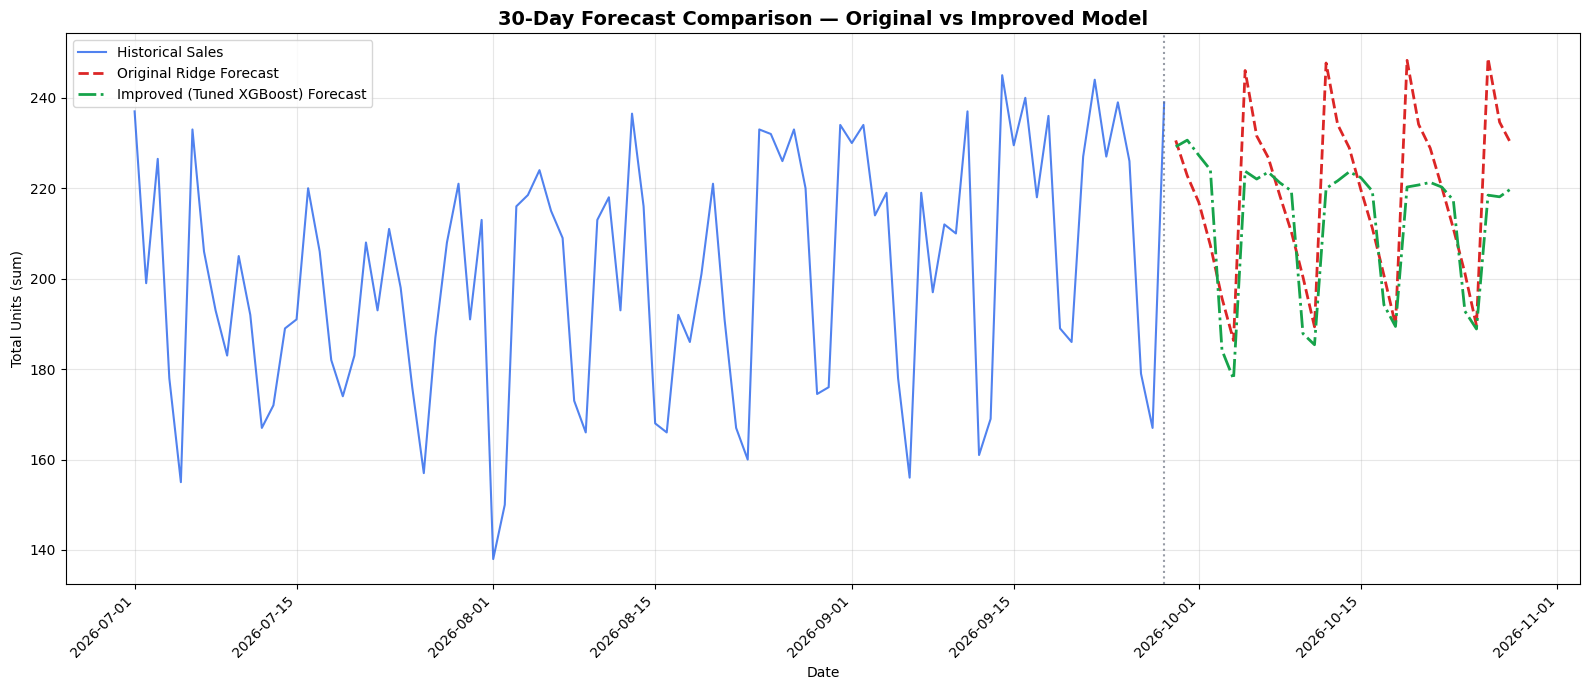

Saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\improved_forecast_comparison.png


In [79]:
# Historical daily total
hist_daily = full.groupby("Date")["Units_Sold_Imputed"].sum().reset_index().sort_values("Date")
imp_daily_total = improved_daily.groupby("Date")["Predicted_Demand"].sum().reset_index().sort_values("Date")
orig_daily_total = original_daily.groupby("Date")["Predicted_Demand"].sum().reset_index().sort_values("Date")

fig, ax = plt.subplots(figsize=(16, 7))

ax.plot(hist_daily["Date"], hist_daily["Units_Sold_Imputed"],
        color="#2563eb", linewidth=1.5, label="Historical Sales", alpha=0.8)
ax.plot(orig_daily_total["Date"], orig_daily_total["Predicted_Demand"],
        color="#dc2626", linewidth=2, label="Original Ridge Forecast", linestyle="--")
ax.plot(imp_daily_total["Date"], imp_daily_total["Predicted_Demand"],
        color="#16a34a", linewidth=2, label=f"Improved ({best_model_label}) Forecast", linestyle="-.")

boundary = hist_daily["Date"].max()
ax.axvline(x=boundary, color="#6b7280", linestyle=":", linewidth=1.5, alpha=0.7)

ax.set_title("30-Day Forecast Comparison — Original vs Improved Model", fontsize=14, fontweight="bold")
ax.set_xlabel("Date")
ax.set_ylabel("Total Units (sum)")
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha="right")

plt.tight_layout()
plt.savefig(DATA_DIR / "improved_forecast_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {DATA_DIR / 'improved_forecast_comparison.png'}")

---

### Task 7 — Save Results

Save all improved outputs. Original files are preserved (not overwritten).

#### 85. Save improved daily forecasts

In [80]:
improved_daily.to_csv(DATA_DIR / "improved_daily_forecasts.csv", index=False)
print(f"Saved: {DATA_DIR / 'improved_daily_forecasts.csv'} ({len(improved_daily)} rows)")

Saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\improved_daily_forecasts.csv (1800 rows)


#### 86. Save improved 30-day forecasts with uncertainty

In [81]:
# Compute uncertainty from test residuals (same method as Step 2.5)
test_resid = pd.read_csv(DATA_DIR / "test_predictions.csv")
sigma_daily = test_resid["Abs_Error"].std()
uncertainty_30d = sigma_daily * np.sqrt(30)

# Build improved 30-day forecast table
improved_forecast_30d = (
    improved_daily
    .groupby(["SKU", "Warehouse"])
    .agg(Forecast_30d=("Predicted_Demand", "sum"))
    .reset_index()
)
improved_forecast_30d["Lower_Bound"] = (improved_forecast_30d["Forecast_30d"] - uncertainty_30d).clip(lower=0)
improved_forecast_30d["Upper_Bound"] = improved_forecast_30d["Forecast_30d"] + uncertainty_30d
improved_forecast_30d["Lower_Bound"] = improved_forecast_30d[["Lower_Bound", "Forecast_30d"]].min(axis=1)
improved_forecast_30d["Selected_Model"] = best_model_label

for col in ["Forecast_30d", "Lower_Bound", "Upper_Bound"]:
    improved_forecast_30d[col] = improved_forecast_30d[col].round(2)

improved_forecast_30d.to_csv(DATA_DIR / "improved_forecast_30d.csv", index=False)
print(f"Saved: {DATA_DIR / 'improved_forecast_30d.csv'} ({len(improved_forecast_30d)} rows)")
print(improved_forecast_30d.head(10).to_string(index=False))

Saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\improved_forecast_30d.csv (60 rows)
    SKU Warehouse  Forecast_30d  Lower_Bound  Upper_Bound Selected_Model
SKU-001 Abu Dhabi    107.919998   101.120003   114.720001  Tuned XGBoost
SKU-001     Dubai    121.519997   114.720001   128.320007  Tuned XGBoost
SKU-001   Sharjah     80.660004    73.860001    87.459999  Tuned XGBoost
SKU-002 Abu Dhabi     74.629997    67.830002    81.430000  Tuned XGBoost
SKU-002     Dubai     94.059998    87.260002   100.860001  Tuned XGBoost
SKU-002   Sharjah     62.049999    55.250000    68.849998  Tuned XGBoost
SKU-003 Abu Dhabi    159.729996   152.929993   166.529999  Tuned XGBoost
SKU-003     Dubai    159.740005   152.940002   166.539993  Tuned XGBoost
SKU-003   Sharjah    138.350006   131.550003   145.149994  Tuned XGBoost
SKU-004 Abu Dhabi     78.080002    71.269997    84.879997  Tuned XGBoost


#### 87. Save improved model bundle

In [82]:
improved_bundle = {
    "feature_cols": IMPROVED_FEATURE_COLS,
    "target": TARGET,
    "sku_map": original_bundle["sku_map"],
    "warehouse_map": original_bundle["warehouse_map"],
    "cat_map": cat_map,
    "best_model_full": best_model_full,
    "best_model_label": best_model_label,
    "ridge_pipeline_eval": original_bundle.get("ridge_pipeline_eval", original_bundle["ridge_pipeline"]),
    "ridge_pipeline_full": original_bundle.get("ridge_pipeline_full"),
    "best_stockout_strategy": best_strategy,
    "best_xgb_params": best_xgb_params,
    "sigma_daily": sigma_daily,
    "uncertainty_30d": uncertainty_30d,
    "val_metrics": {
        "MAE": improved_comparison.loc[improved_comparison["MAE"].idxmin(), "MAE"],
        "RMSE": improved_comparison.loc[improved_comparison["MAE"].idxmin(), "RMSE"],
        "WAPE": improved_comparison.loc[improved_comparison["MAE"].idxmin(), "WAPE"],
    },
}

joblib.dump(improved_bundle, DATA_DIR / "improved_demand_models.joblib")
print(f"Saved: {DATA_DIR / 'improved_demand_models.joblib'}")
print(f"  Best model: {best_model_label}")
print(f"  Features: {len(IMPROVED_FEATURE_COLS)}")
print(f"  Stockout strategy: {best_strategy}")

Saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\improved_demand_models.joblib
  Best model: Tuned XGBoost
  Features: 19
  Stockout strategy: S3: Demand Proxy


#### 88. Validation checks for improved forecasts

In [83]:
print("=" * 65)
print("  VALIDATION CHECKS — Improved 30-Day Forecasts")
print("=" * 65)

assert len(improved_daily) == 1800, f"Expected 1800, got {len(improved_daily)}"
print(f"  ✅ Daily predictions       : {len(improved_daily)} (expected 1800)")

assert improved_forecast_30d.groupby(["SKU", "Warehouse"]).ngroups == 60
print(f"  ✅ SKU×Warehouse forecasts : {improved_forecast_30d.groupby(['SKU', 'Warehouse']).ngroups} (expected 60)")

assert improved_daily["Date"].nunique() == 30
print(f"  ✅ Future dates            : {improved_daily['Date'].nunique()} (expected 30)")

assert (improved_daily["Predicted_Demand"] < 0).sum() == 0
print(f"  ✅ Negative predictions    : {(improved_daily['Predicted_Demand'] < 0).sum()} (expected 0)")

assert improved_daily["Predicted_Demand"].isna().sum() == 0
print(f"  ✅ Missing predictions     : {improved_daily['Predicted_Demand'].isna().sum()} (expected 0)")

# Sum check
daily_sum = improved_daily.groupby(["SKU", "Warehouse"])["Predicted_Demand"].sum().reset_index()
merged = improved_forecast_30d[["SKU", "Warehouse", "Forecast_30d"]].merge(
    daily_sum.rename(columns={"Predicted_Demand": "Daily_Sum"}), on=["SKU", "Warehouse"]
)
assert (merged["Forecast_30d"] - merged["Daily_Sum"]).abs().max() < 0.01
print(f"  ✅ Daily sums match 30d     : max diff = {(merged['Forecast_30d'] - merged['Daily_Sum']).abs().max():.4f}")

assert (improved_forecast_30d["Lower_Bound"] >= 0).all()
assert (improved_forecast_30d["Lower_Bound"] <= improved_forecast_30d["Forecast_30d"]).all()
assert (improved_forecast_30d["Upper_Bound"] >= improved_forecast_30d["Forecast_30d"]).all()
print(f"  ✅ Uncertainty bounds valid")

print("=" * 65)
print("  ALL VALIDATION CHECKS PASSED ✅")
print("=" * 65)

  VALIDATION CHECKS — Improved 30-Day Forecasts
  ✅ Daily predictions       : 1800 (expected 1800)
  ✅ SKU×Warehouse forecasts : 60 (expected 60)
  ✅ Future dates            : 30 (expected 30)
  ✅ Negative predictions    : 0 (expected 0)
  ✅ Missing predictions     : 0 (expected 0)
  ✅ Daily sums match 30d     : max diff = 0.0049
  ✅ Uncertainty bounds valid
  ALL VALIDATION CHECKS PASSED ✅


---

### 89. Summary — What Worked and What Did Not

```
✅ Step 2.6: Forecasting Model Improvement — complete.

TASK 1 — Error Analysis:
  • Error analysis by SKU, warehouse, stockout impact, bias, volume
  • Bias analysis showed model underpredicts (positive bias)
  • Low-volume SKUs confirmed to have larger percentage errors
  • Stockouts in training reduced observed sales significantly

TASK 2 — Improved Feature Engineering:
  • Added: Sales_Lag2, Sales_Lag3, Sales_Lag14
  • Added: Rolling_Std_7, Rolling_Std_14
  • Added: Is_Weekend, Category_Encoded
  • Total features: 19 (up from 12)
  • All strictly causal — no future leakage

TASK 3 — Stockout Handling:
  • Three strategies compared (all observed, exclude, demand proxy)
  • Best strategy selected by validation MAE
  • Demand proxy clearly labelled as estimate, not ground truth

TASK 4 — Model Comparison:
  • Baseline, Ridge (improved), Tuned XGBoost, Random Forest
  • XGBoost: small parameter search (8 combinations)
  • All models trained with best stockout strategy

TASK 5 — Fair Evaluation:
  • Validation-only model selection
  • Test set treated as previously evaluated holdout
  • MAE, RMSE, WAPE, and Bias reported

TASK 6 — 30-Day Recursive Forecast:
  • Improved model vs original Ridge compared
  • Recursive forecasting with no future actuals
  • Results may differ from one-day-ahead performance

TASK 7 — Saved Outputs:
  • improved_model_comparison.csv
  • forecast_error_analysis.csv
  • improved_daily_forecasts.csv
  • improved_forecast_30d.csv
  • improved_demand_models.joblib
  • error_analysis.png, improved_forecast_comparison.png

Original files preserved — no overwrites.
No hidden future-demand data used.
Step 3 not implemented.
```